# Исследование спектральных данных

Загружаем в `df` все CSV с измерениями из `data/**/samples/`, включая
`AM`, `FM`, `Noise`, дополнительные `FM_dop` и архив `old`.
Старые исключения не применяются; записи не фильтруются и не усредняются.
Одна строка — одна частотная точка одного временного среза.

`source_set` показывает раздел данных, `run_id` — запуск измерения,
`sample_csv` — путь к исходному CSV относительно `data/`.
Класс берётся из CSV: дополнительные FM остаются классом `FM`.


## Отбор записей 27.10.2026 — текущий состав

Дополнительно исключены все профили FM на 90,8; 91,2; 91,6; 92,0;
92,4; 92,8; 93,2; 98,8 МГц — 24 записи.

Из FM_dop исключены центры 87,36; 88,04; 89,64; 89,76 МГц,
а также все центры внутри диапазонов 88,16–88,96; 90,12–90,66;
91,02–95,46; 96,62–96,88; 100,24–107,98 МГц, включая границы — 88 записей.

Эти 112 записей хранятся вне `data/` в
`.local/archive/excluded_2026-10-27_revision3/`.
`manifest.json` содержит точные пути, правила отбора и SHA256 файлов.
Предыдущие согласованные исключения сохраняются; AM, Noise и old
на этом этапе не изменялись. Старые manifest отражают историю своих этапов.

Текущий `df`: 169 записей — 48 AM, 27 FM, 15 FM_dop, 66 Noise и 13 old.
Из старых сохранены все AM, FM 87,9 / 101,8 / 104,7 МГц и
Noise 87,7 / 93,4 / 113,9 МГц. Новые Noise сохранены полностью.
Сама 100,1 МГц в основном FM сохранена во всех трёх профилях.

Дополнительный этап: исключены оставшиеся FM_dop с центрами 96,94–98,88 МГц
включительно: 96,94; 96,98; 98,66; 98,72; 98,88 МГц — 5 записей.
Архив: `.local/archive/excluded_2026-10-27_revision4/`, журнал — `manifest.json`.


In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Работает при запуске ядра из корня проекта или папки scripts.
working_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (working_dir, *working_dir.parents)
     if (folder / "get_data.py").is_file() and (folder / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Запустите ноутбук из корня проекта или папки scripts.")

DATA_ROOT = PROJECT_ROOT / "data"


In [2]:
sample_files = sorted(DATA_ROOT.glob("**/samples/*.csv"))
if not sample_files:
    raise FileNotFoundError(f"Не найдены CSV измерений в {DATA_ROOT}")

frames = []
for sample_csv in sample_files:
    frame = pd.read_csv(sample_csv)
    relative_path = sample_csv.relative_to(DATA_ROOT)
    frame["source_set"] = relative_path.parts[0]
    frame["run_id"] = sample_csv.parent.parent.name
    frame["sample_csv"] = relative_path.as_posix()
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
del frames, frame

# Повторяющиеся идентификаторы храним компактно, значения измерений сохраняем.
for column in ("sample_id", "class_name", "sample_group_name",
               "source_set", "run_id", "sample_csv"):
    df[column] = df[column].astype("category")

print(f"Загружено файлов: {len(sample_files):,}")
print(f"Размер df: {df.shape[0]:,} строк × {df.shape[1]} столбцов")


Загружено файлов: 169
Размер df: 4,233,450 строк × 10 столбцов


In [3]:
display(df.head())

# Отдельно показываем новые, дополнительные и архивные записи.
display(
    df.groupby(["source_set", "class_name"], observed=True)
    .agg(
        files=("sample_csv", "nunique"),
        rows=("point_idx", "size"),
    )
)


,sample_id,class_name,sample_group_name,sweep_idx,point_idx,frequency_hz,amplitude_dbm,source_set,run_id,sample_csv
0,AM_100_65_20261005_141111_463035_0000,AM,AM_100_65,0,0,100525000.0,10.643295,AM,20261005_141111_463035,AM/AM_100_65/20261005_141111_463035/samples/AM...
1,AM_100_65_20261005_141111_463035_0000,AM,AM_100_65,0,1,100525500.0,8.454544,AM,20261005_141111_463035,AM/AM_100_65/20261005_141111_463035/samples/AM...
2,AM_100_65_20261005_141111_463035_0000,AM,AM_100_65,0,2,100526000.0,6.284431,AM,20261005_141111_463035,AM/AM_100_65/20261005_141111_463035/samples/AM...
3,AM_100_65_20261005_141111_463035_0000,AM,AM_100_65,0,3,100526500.0,3.766975,AM,20261005_141111_463035,AM/AM_100_65/20261005_141111_463035/samples/AM...
4,AM_100_65_20261005_141111_463035_0000,AM,AM_100_65,0,4,100527000.0,2.222626,AM,20261005_141111_463035,AM/AM_100_65/20261005_141111_463035/samples/AM...


files     rows
source_set class_name                
AM         AM             48  1202400
FM         FM             27   676350
FM_dop     FM             15   375750
Noise      Noise          66  1653300
old        AM              7   175350
           FM              3    75150
           Noise           3    75150

## Коллекции спектров всех измерений

Один график соответствует одному исходному CSV (отдельному запуску), поэтому
разные профили анализатора и настройки генератора не смешиваются.
Каждая страница содержит до 16 графиков (4 × 4); последняя может быть неполной.
Страницы разделены по `source_set` и классу, внутри отсортированы по частоте.

Линия — средняя записанная амплитуда по всем временным срезам в каждой
частотной точке. Полоса — среднее ± одно стандартное отклонение между срезами.
Усреднение выполняется в исходных единицах dBm, без перевода в линейную мощность.
По горизонтали — смещение от центра измерения в кГц. Центральная частота,
профиль и параметры указаны в заголовке. Пределы амплитуды одинаковы
для всех страниц одного раздела и класса; ширина частотного окна может различаться.

По умолчанию выводятся все записи, включая `FM_dop` и `old`. Для отдельного
просмотра ЧМ или конкретных частот можно изменить фильтры в последней ячейке.


In [4]:
import json
import math

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Каталог запусков: одна строка на CSV, без объединения разных профилей.
measurements = (
    df.groupby("sample_csv", observed=True)
    .agg(
        source_set=("source_set", "first"),
        class_name=("class_name", "first"),
        sample_group_name=("sample_group_name", "first"),
        run_id=("run_id", "first"),
        frequency_min_hz=("frequency_hz", "min"),
        frequency_max_hz=("frequency_hz", "max"),
        sweeps=("sweep_idx", "nunique"),
    )
    .reset_index()
)

configs = []
for sample_csv in measurements["sample_csv"]:
    config_path = (DATA_ROOT / str(sample_csv)).parent.parent / "run_config.json"
    config = json.loads(config_path.read_text(encoding="utf-8")) if config_path.exists() else {}
    configs.append({
        key: config.get(key)
        for key in (
            "center_freq_mhz", "span_khz", "analyzer_profile", "rbw_hz", "vbw_hz",
            "generator_level_dbm", "generator_depth_percent", "generator_modulation_freq_khz",
        )
    })
measurements = pd.concat([measurements, pd.DataFrame(configs)], axis=1)
fallback_center = (measurements["frequency_min_hz"] + measurements["frequency_max_hz"]) / 2e6
measurements["center_freq_mhz"] = measurements["center_freq_mhz"].fillna(fallback_center)
measurements["analyzer_profile"] = measurements["analyzer_profile"].fillna("исходный профиль")
measurements["span_khz"] = measurements["span_khz"].fillna(
    (measurements["frequency_max_hz"] - measurements["frequency_min_hz"]) / 1e3
)

# Предварительно считаем спектры один раз, чтобы быстро перерисовывать страницы.
spectrum_summary = (
    df.groupby(["sample_csv", "point_idx"], observed=True)
    .agg(
        frequency_hz=("frequency_hz", "mean"),
        amplitude_mean=("amplitude_dbm", "mean"),
        amplitude_std=("amplitude_dbm", "std"),
    )
    .reset_index()
)
spectra = {
    str(sample_csv): spectrum.sort_values("point_idx")
    for sample_csv, spectrum in spectrum_summary.groupby("sample_csv", observed=True)
}
print(f"Подготовлено отдельных спектров: {len(measurements)}")


Подготовлено отдельных спектров: 169


In [5]:
def plot_spectrum_collections(measurements, spectra, source_sets=None,
                              classes=None, centers_mhz=None):
    """Показывает все выбранные записи страницами по 16 спектров."""
    selected = measurements.copy()
    if source_sets is not None:
        selected = selected[selected["source_set"].isin(source_sets)]
    if classes is not None:
        selected = selected[selected["class_name"].isin(classes)]
    if centers_mhz is not None:
        # Допуск 1 Гц нужен только для сравнения чисел с плавающей точкой.
        selected = selected[selected["center_freq_mhz"].apply(
            lambda center: any(abs(center - value) <= 1e-6 for value in centers_mhz)
        )]
    selected = selected.sort_values(
        ["source_set", "class_name", "center_freq_mhz", "analyzer_profile", "run_id", "sample_csv"]
    )
    if selected.empty:
        print("По выбранным фильтрам измерений нет.")
        return pd.DataFrame(columns=["source_set", "class_name", "page", "plots"])

    colors = {"AM": "#2878B5", "FM": "#D66B20", "Noise": "#39875A"}
    page_log = []
    for (source_set, class_name), group in selected.groupby(
        ["source_set", "class_name"], observed=True, sort=True
    ):
        pages = math.ceil(len(group) / 16)
        color = colors.get(str(class_name), "#666666")
        lower_limits, upper_limits = [], []
        for sample_csv in group["sample_csv"]:
            spectrum = spectra[str(sample_csv)]
            std = spectrum["amplitude_std"].fillna(0)
            lower_limits.append((spectrum["amplitude_mean"] - std).min())
            upper_limits.append((spectrum["amplitude_mean"] + std).max())
        lower, upper = min(lower_limits), max(upper_limits)
        padding = max((upper - lower) * 0.06, 1.0)

        for page in range(pages):
            batch = group.iloc[page * 16:(page + 1) * 16]
            fig, axes = plt.subplots(4, 4, figsize=(20, 17), sharey=True,
                                     layout="constrained")
            fig.suptitle(
                f"{source_set} / {class_name} — страница {page + 1} из {pages}"
                f" · измерения {page * 16 + 1}–{page * 16 + len(batch)} из {len(group)}",
                fontsize=17,
            )
            for ax, row in zip(axes.flat, batch.itertuples(index=False)):
                spectrum = spectra[str(row.sample_csv)]
                x = (spectrum["frequency_hz"].to_numpy() - row.center_freq_mhz * 1e6) / 1e3
                mean = spectrum["amplitude_mean"].to_numpy()
                std = spectrum["amplitude_std"].fillna(0).to_numpy()
                ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.20)
                ax.plot(x, mean, color=color, linewidth=1.0)
                details = f"span {row.span_khz:g} кГц"
                if pd.notna(row.rbw_hz) and pd.notna(row.vbw_hz):
                    details += f" · RBW/VBW {row.rbw_hz / 1e3:g}/{row.vbw_hz / 1e3:g} кГц"
                title = (f"{row.class_name} · {row.center_freq_mhz:g} МГц · {row.analyzer_profile}"
                         f"\n{details}\n{row.run_id} · {row.sweeps} срезов")
                if pd.notna(row.generator_level_dbm):
                    title += f"\nГенератор {row.generator_level_dbm:g} dBm"
                    if pd.notna(row.generator_depth_percent):
                        title += f" · АМ {row.generator_depth_percent:g}%"
                    if pd.notna(row.generator_modulation_freq_khz):
                        title += f" · LF {row.generator_modulation_freq_khz:g} кГц"
                ax.set_title(title, fontsize=8.5)
                ax.set_xlabel("Смещение частоты, кГц", fontsize=9)
                ax.set_ylabel("Амплитуда, dBm", fontsize=9)
                ax.set_ylim(lower - padding, upper + padding)
                ax.set_xlim(float(x.min()), float(x.max()))
                ax.tick_params(labelsize=8)
                ax.grid(alpha=0.25)
            for ax in list(axes.flat)[len(batch):]:
                ax.set_visible(False)
            axes.flat[0].legend(handles=[
                Line2D([0], [0], color=color, label="Средний спектр"),
                Patch(facecolor=color, alpha=0.20, label="Среднее ± σ"),
            ], fontsize=7, loc="lower left")
            plt.show()
            plt.close(fig)
            page_log.append({"source_set": str(source_set), "class_name": str(class_name),
                             "page": page + 1, "plots": len(batch)})
    print(f"Показано измерений: {len(selected)}; страниц: {len(page_log)}")
    return pd.DataFrame(page_log)


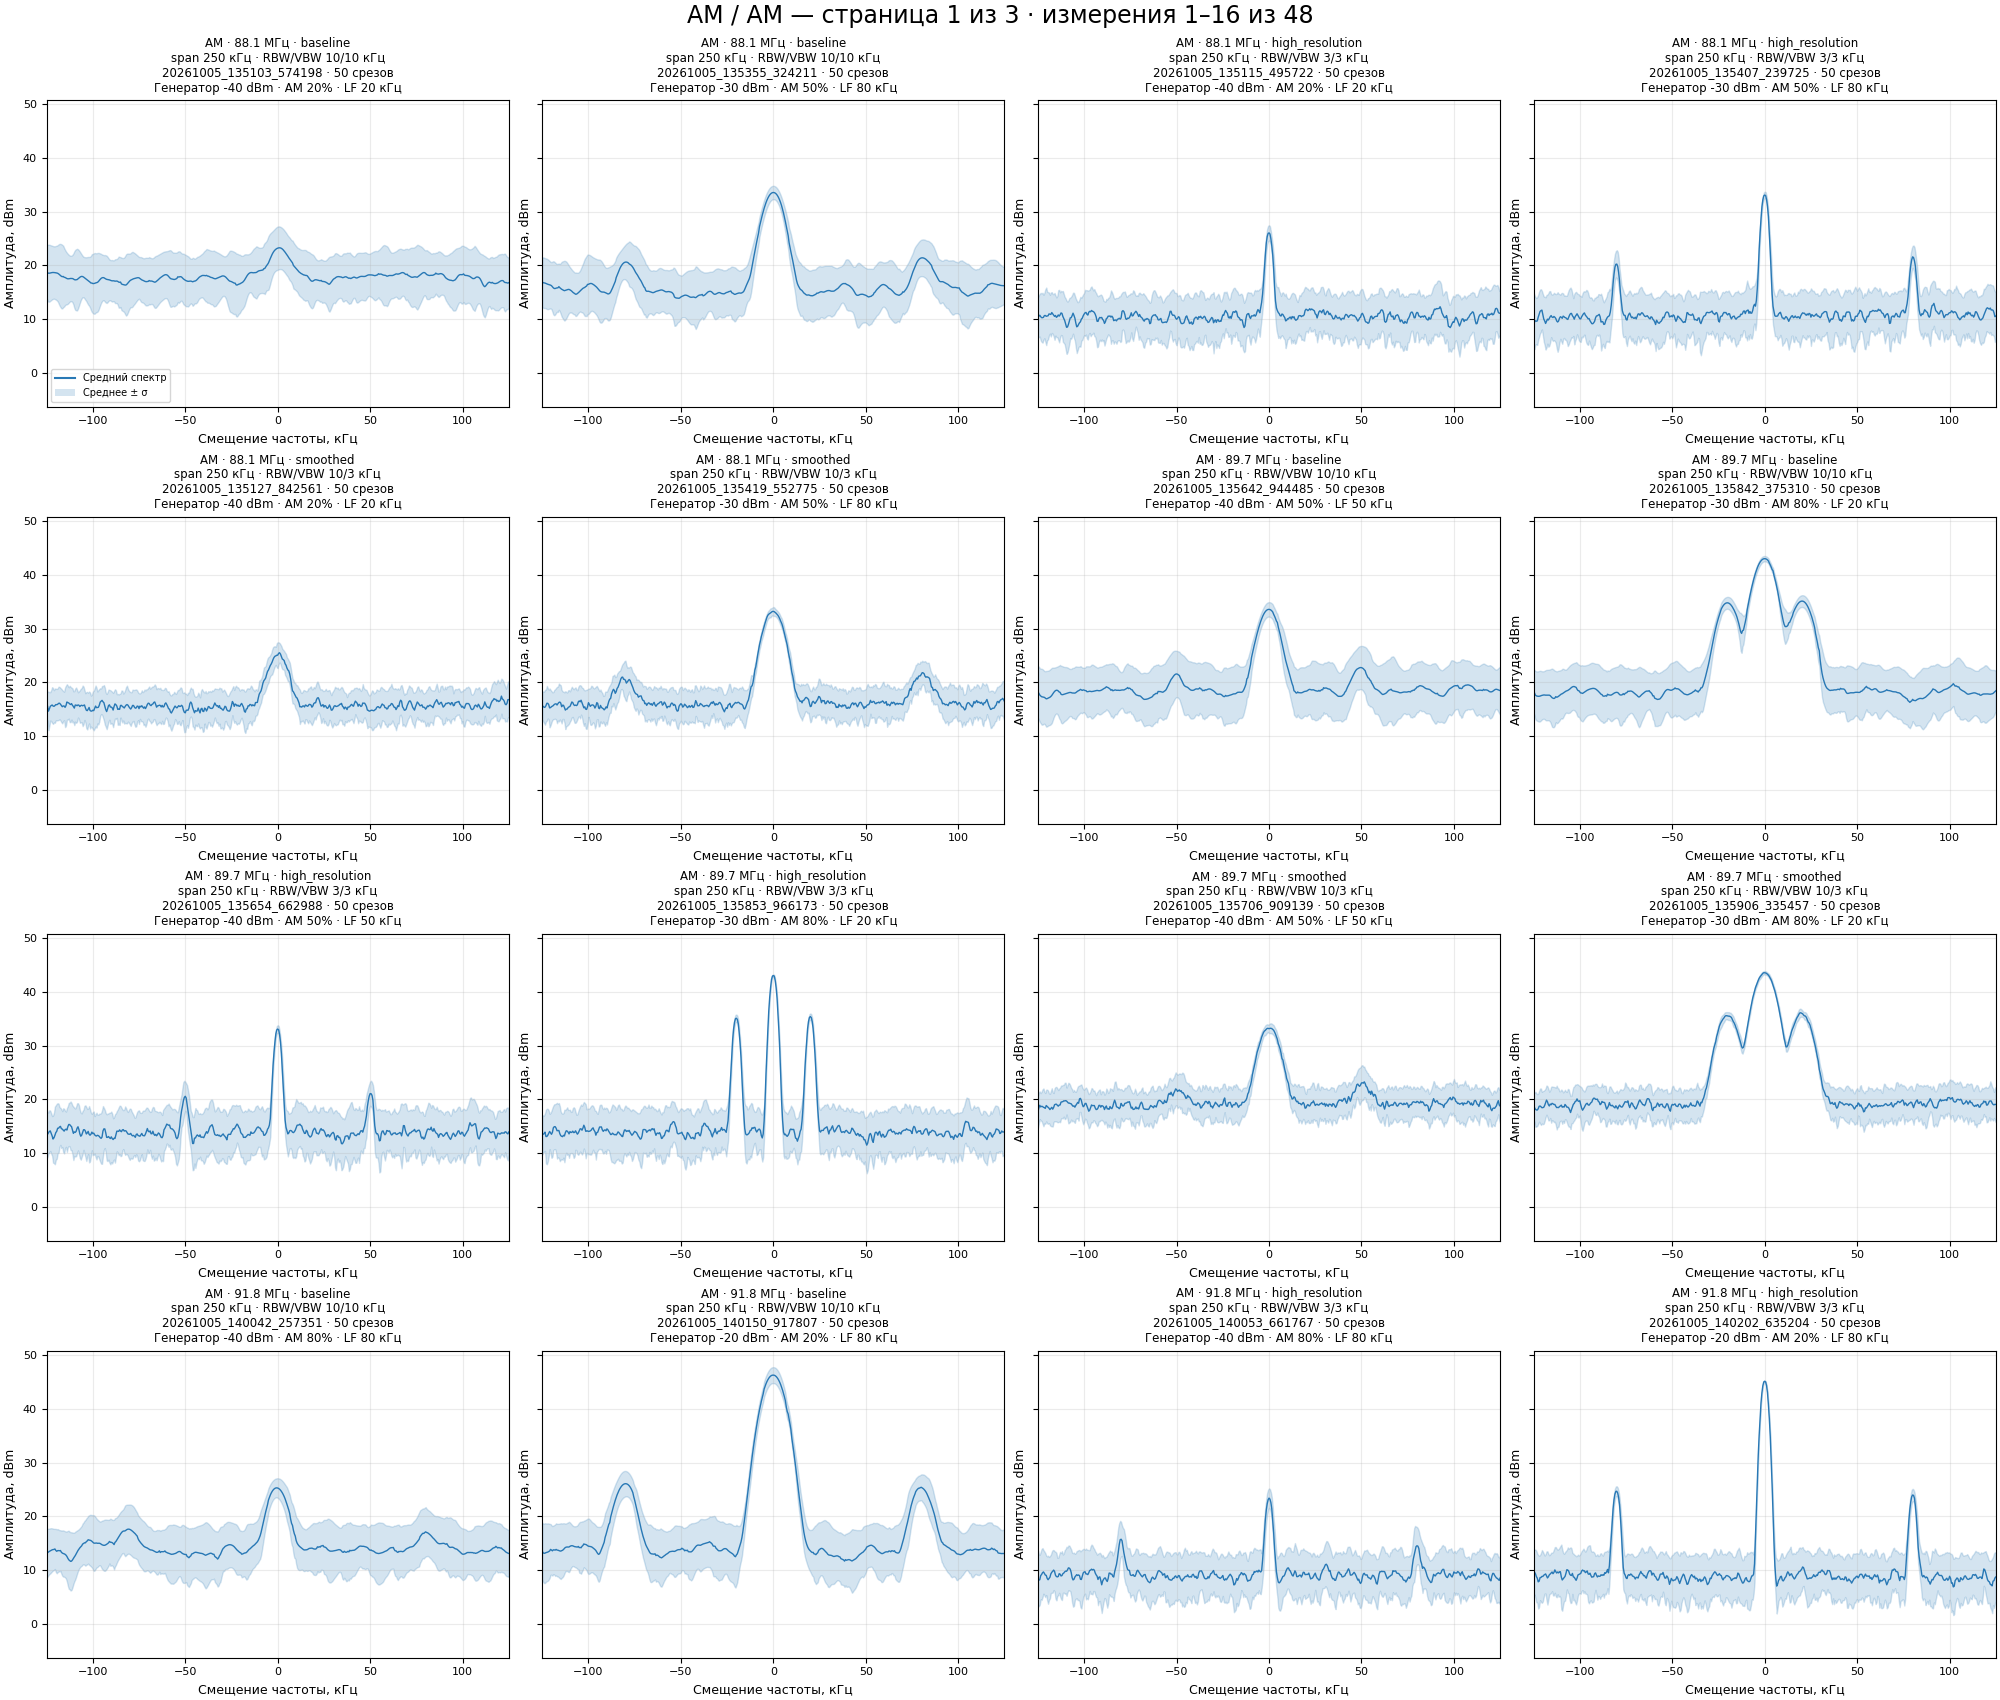

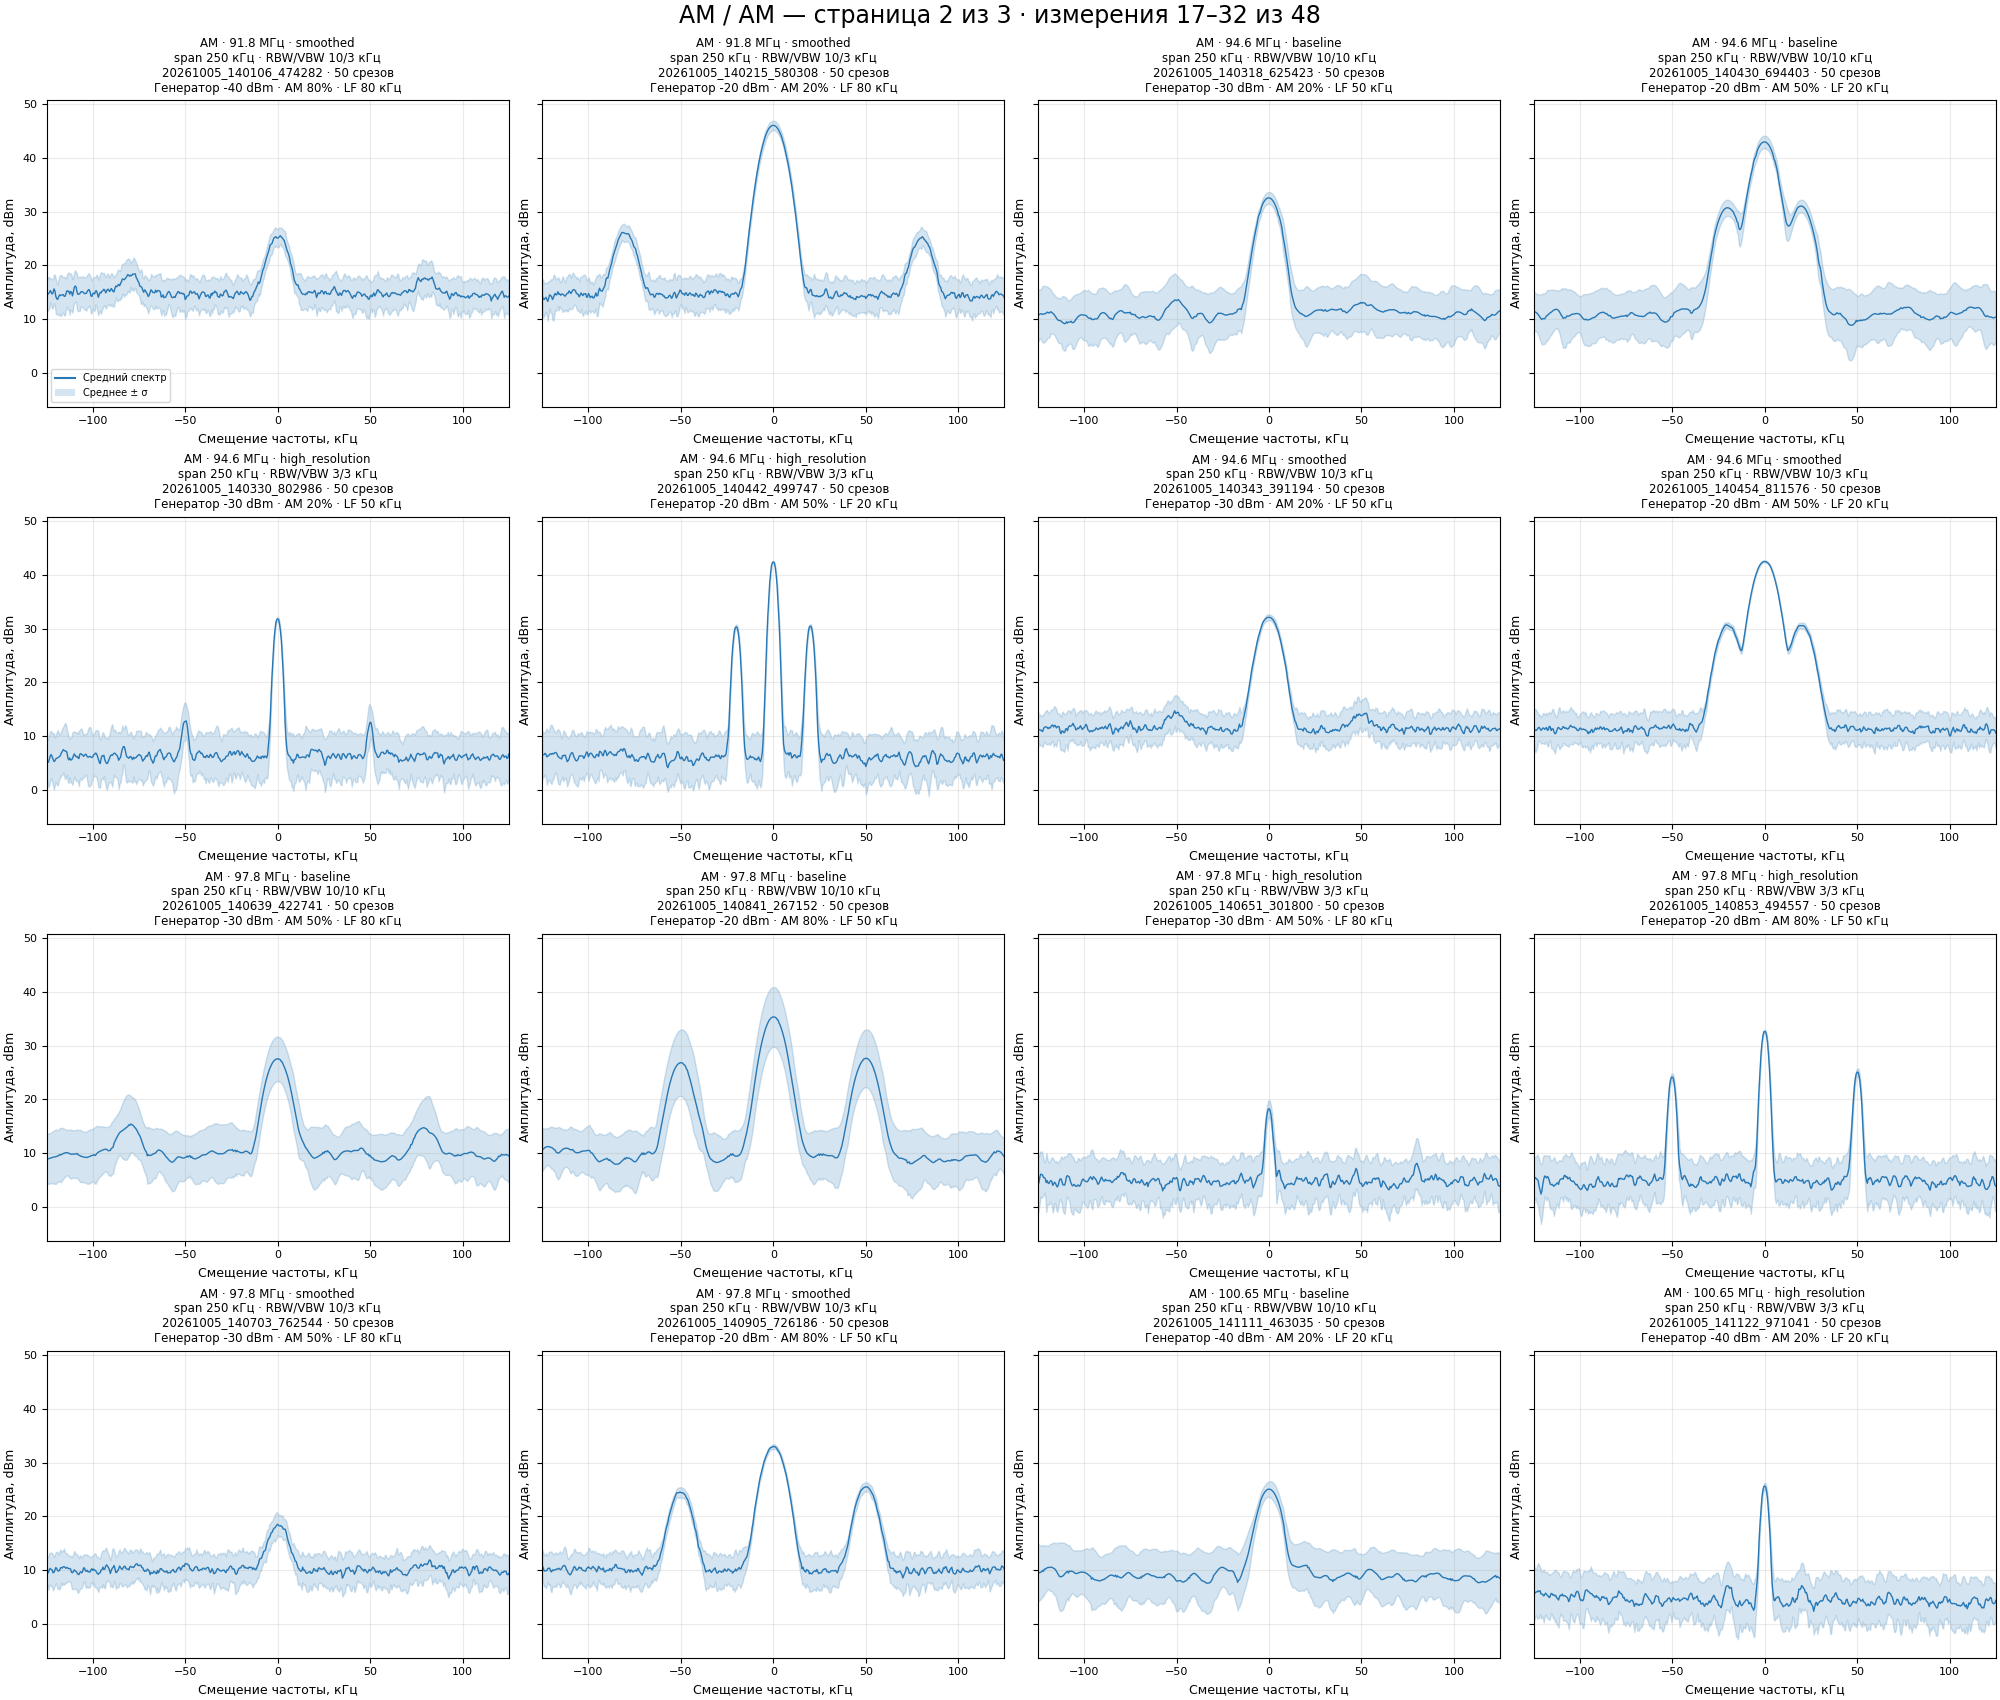

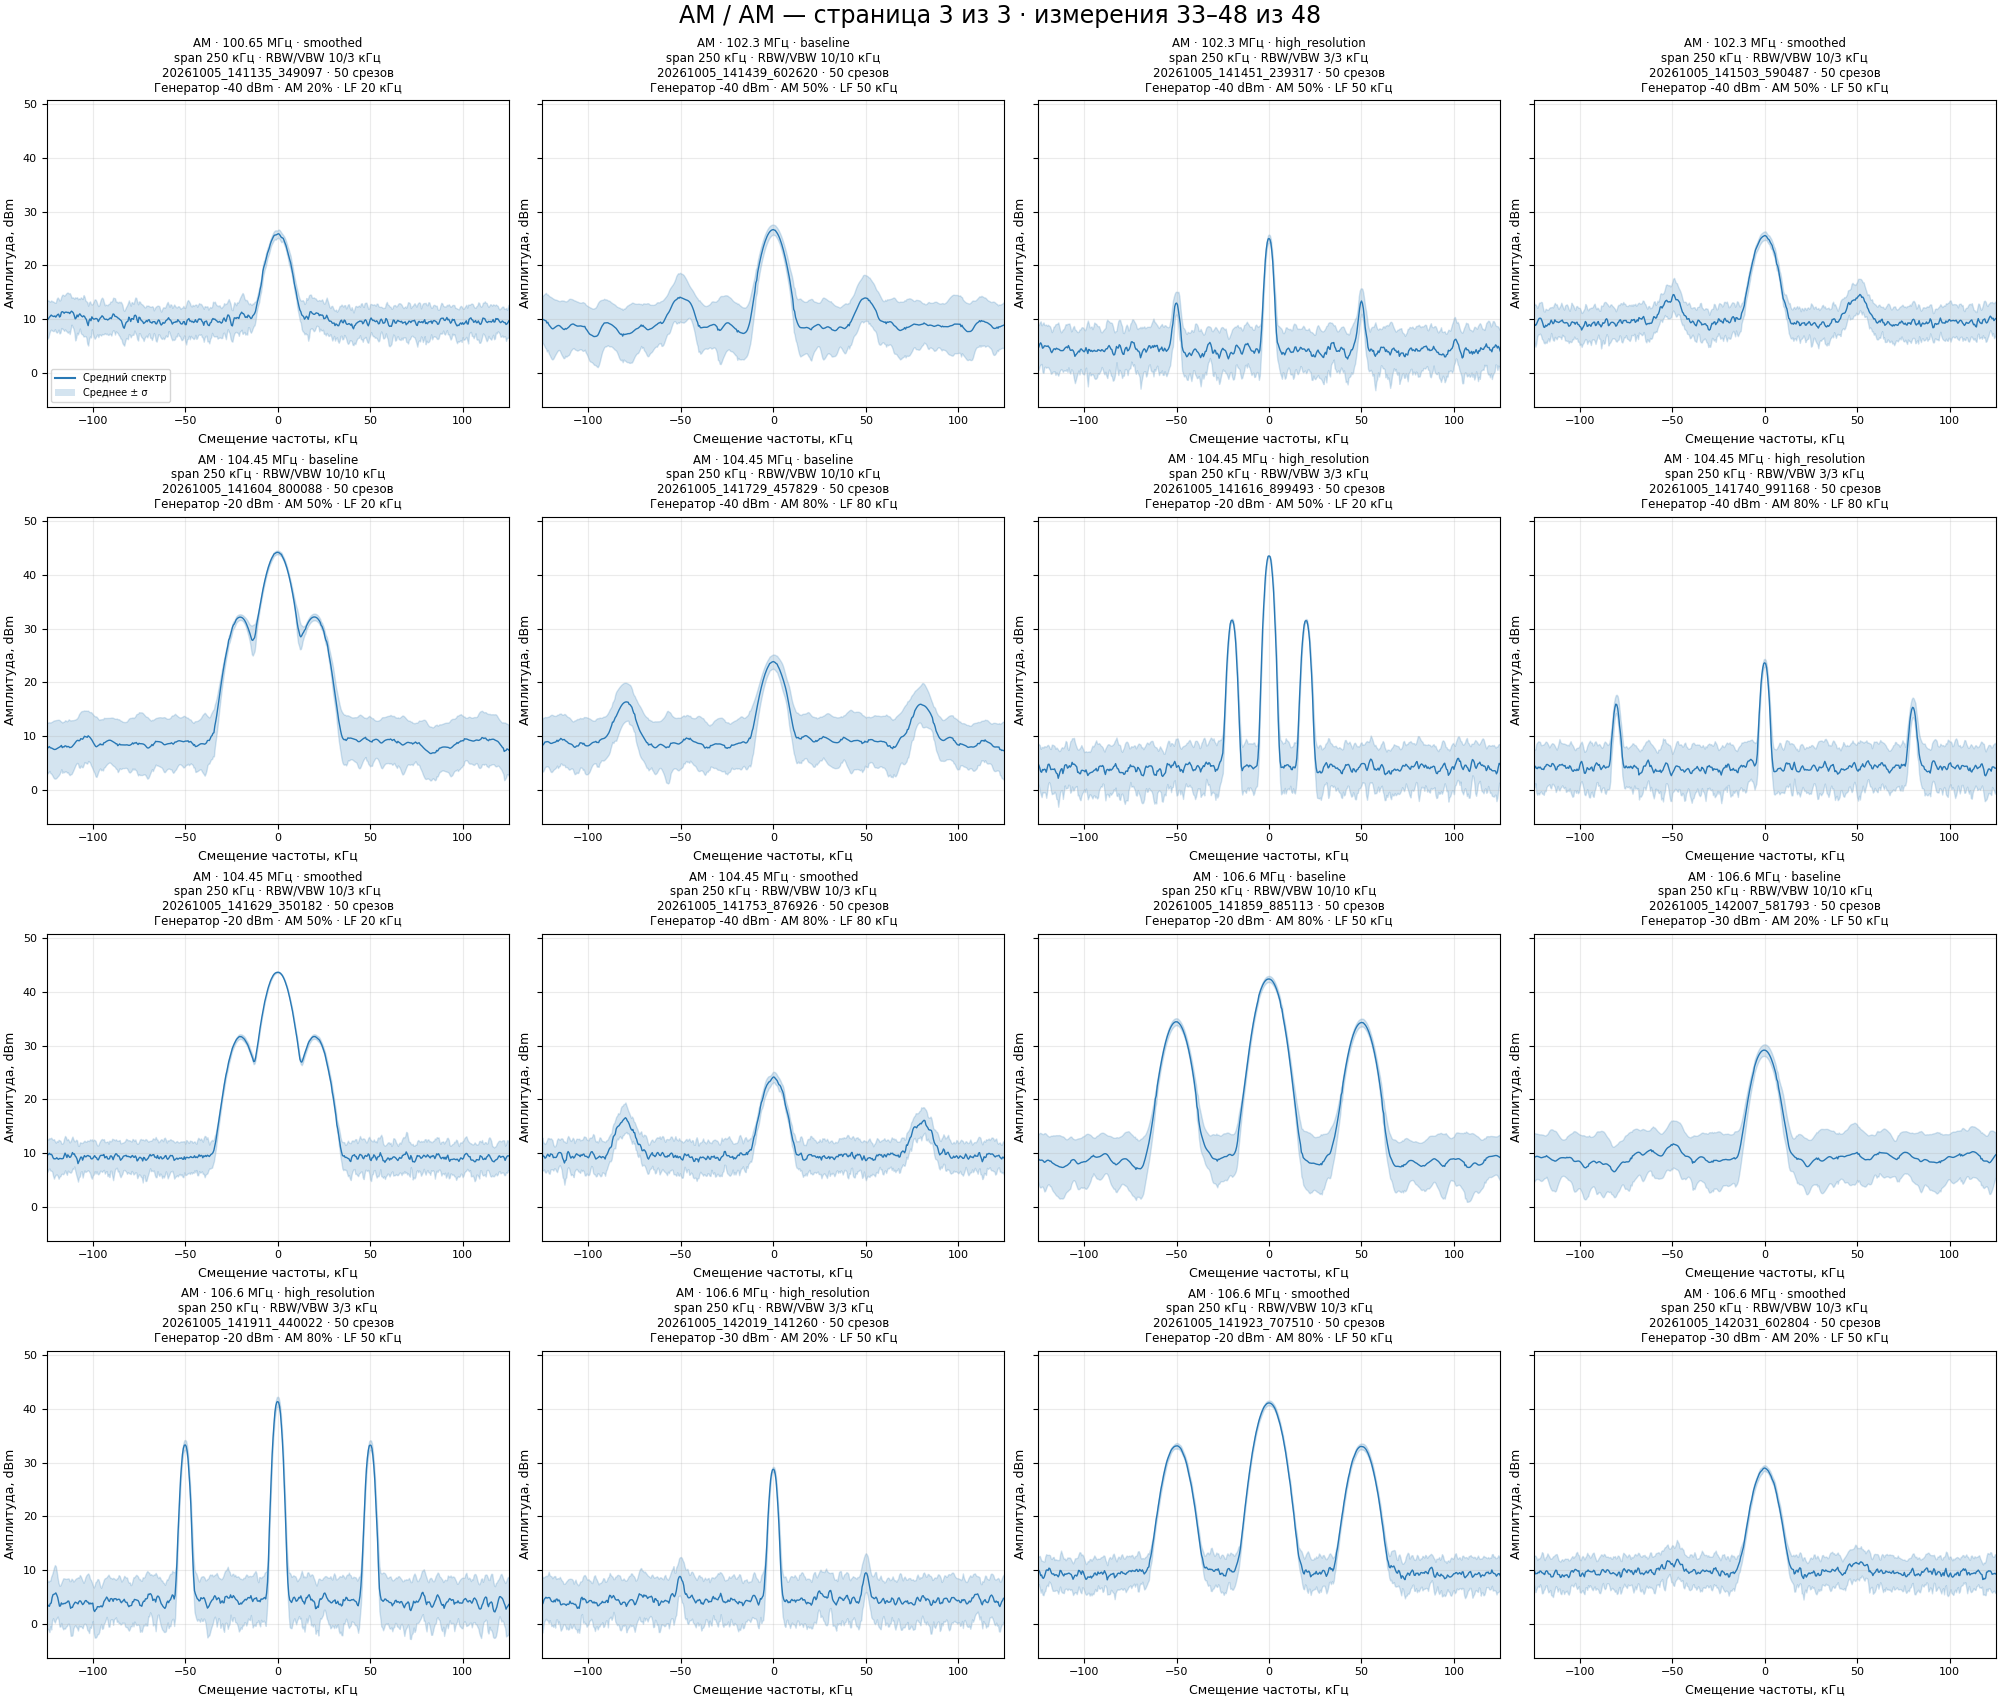

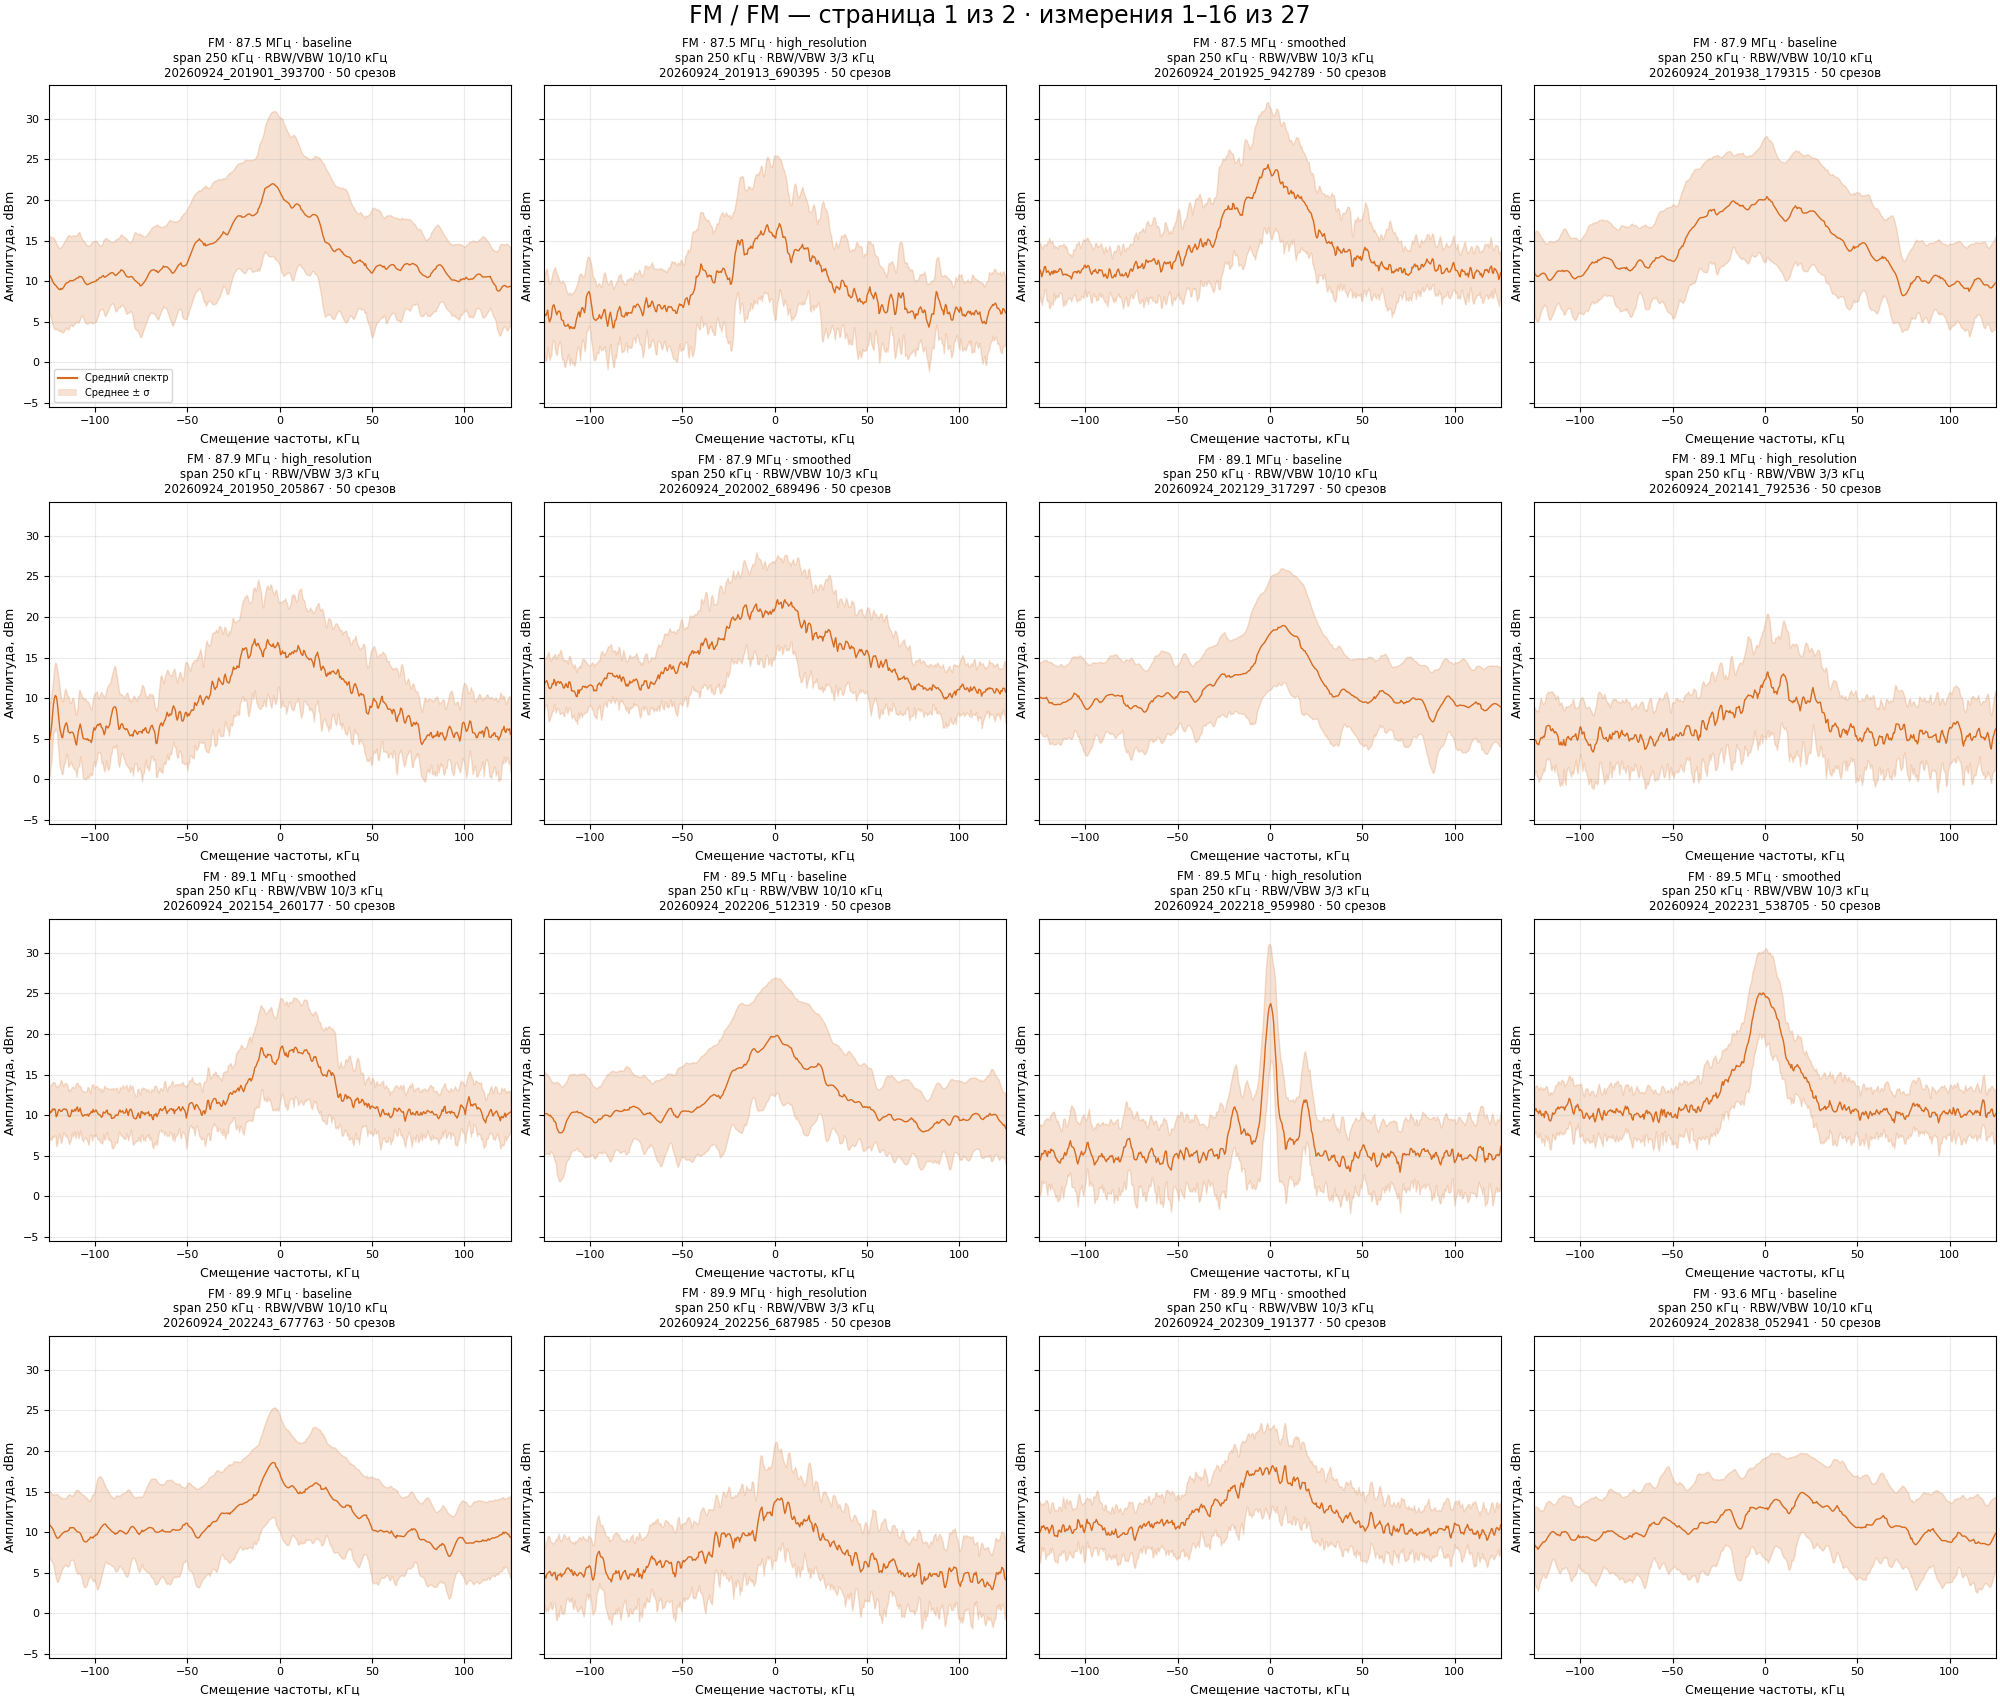

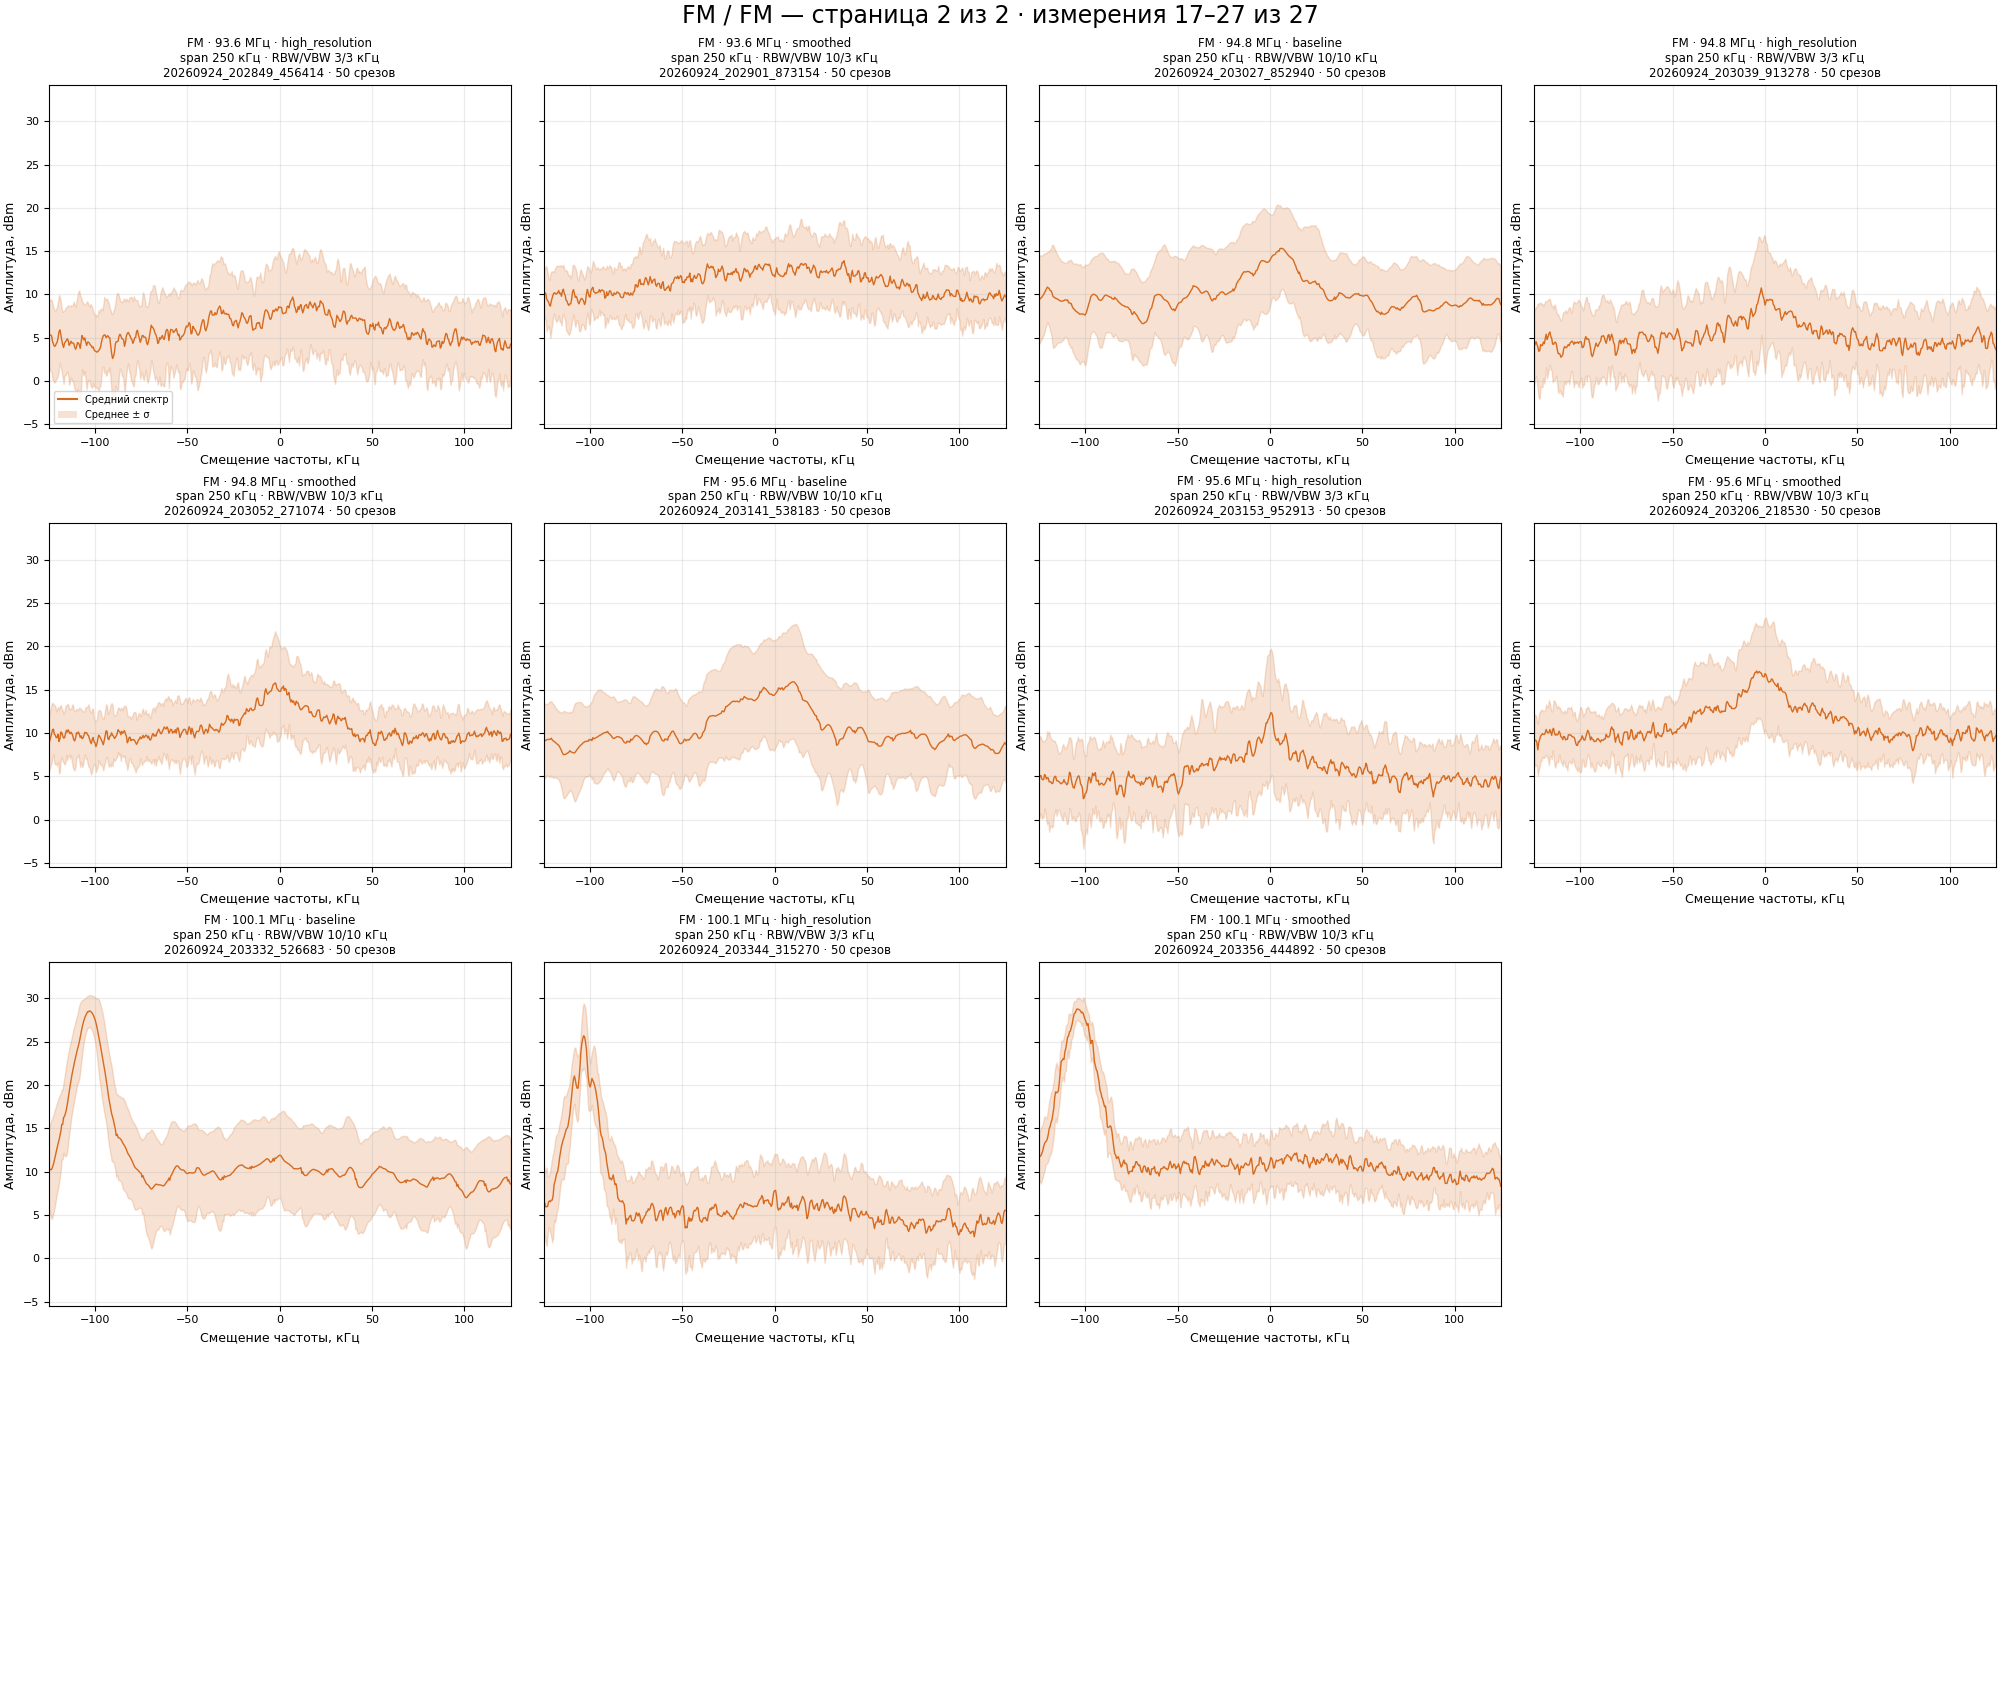

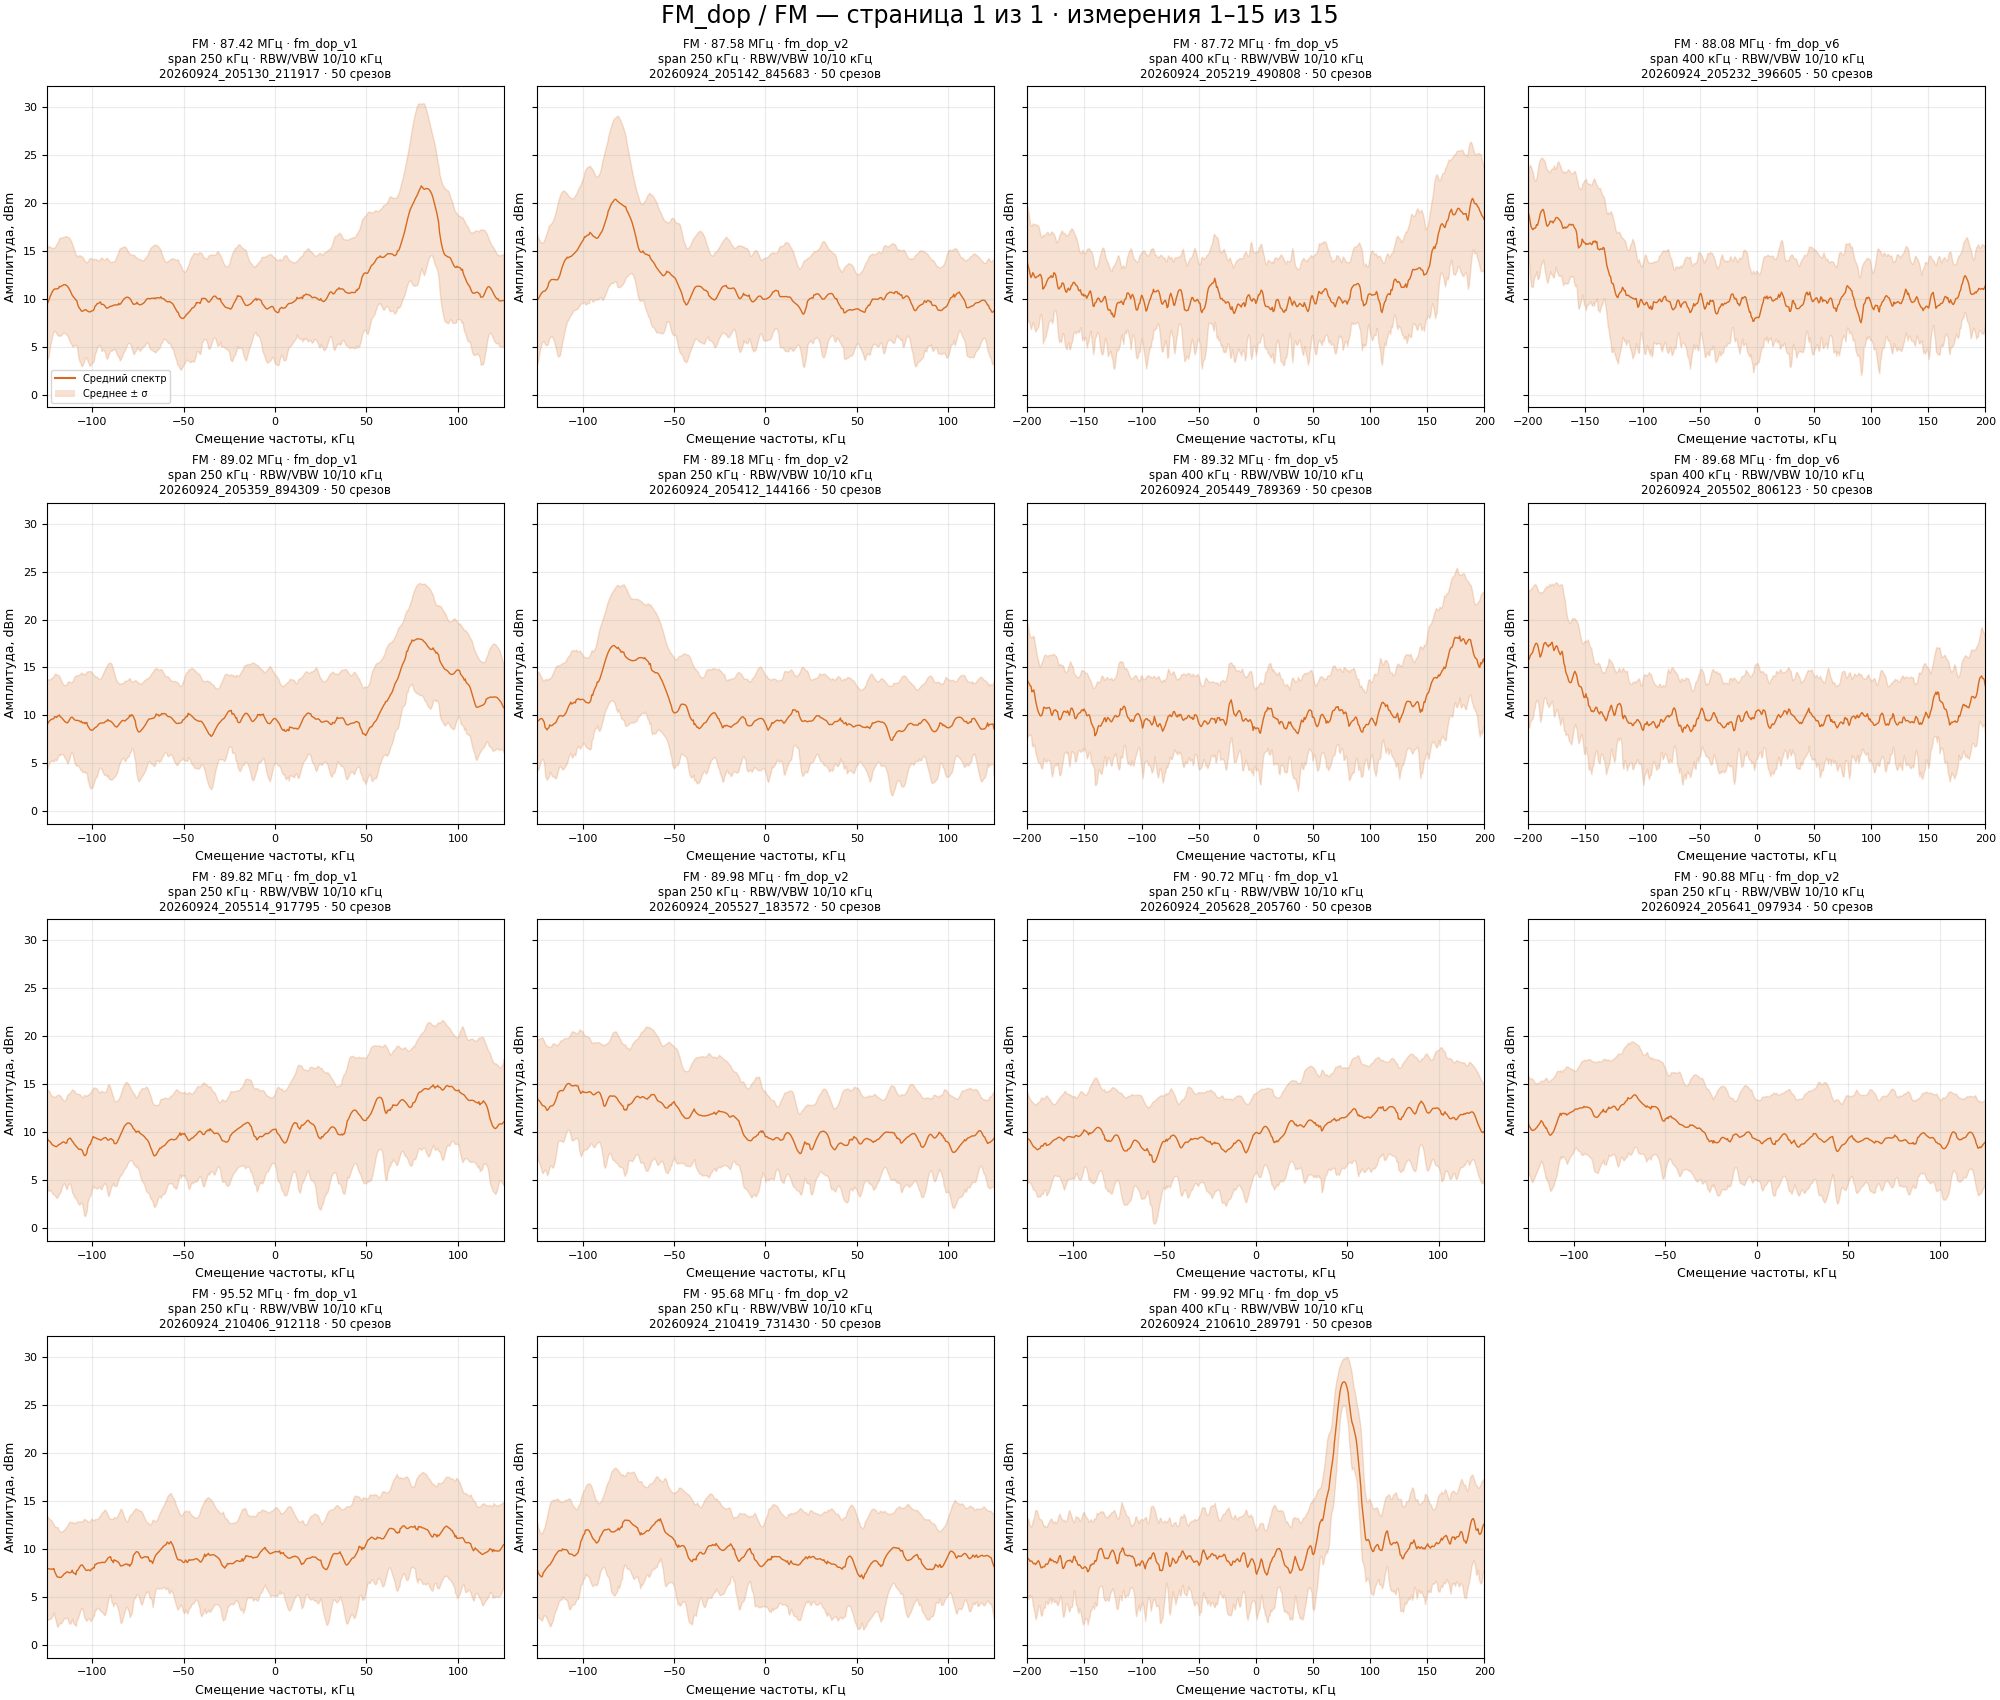

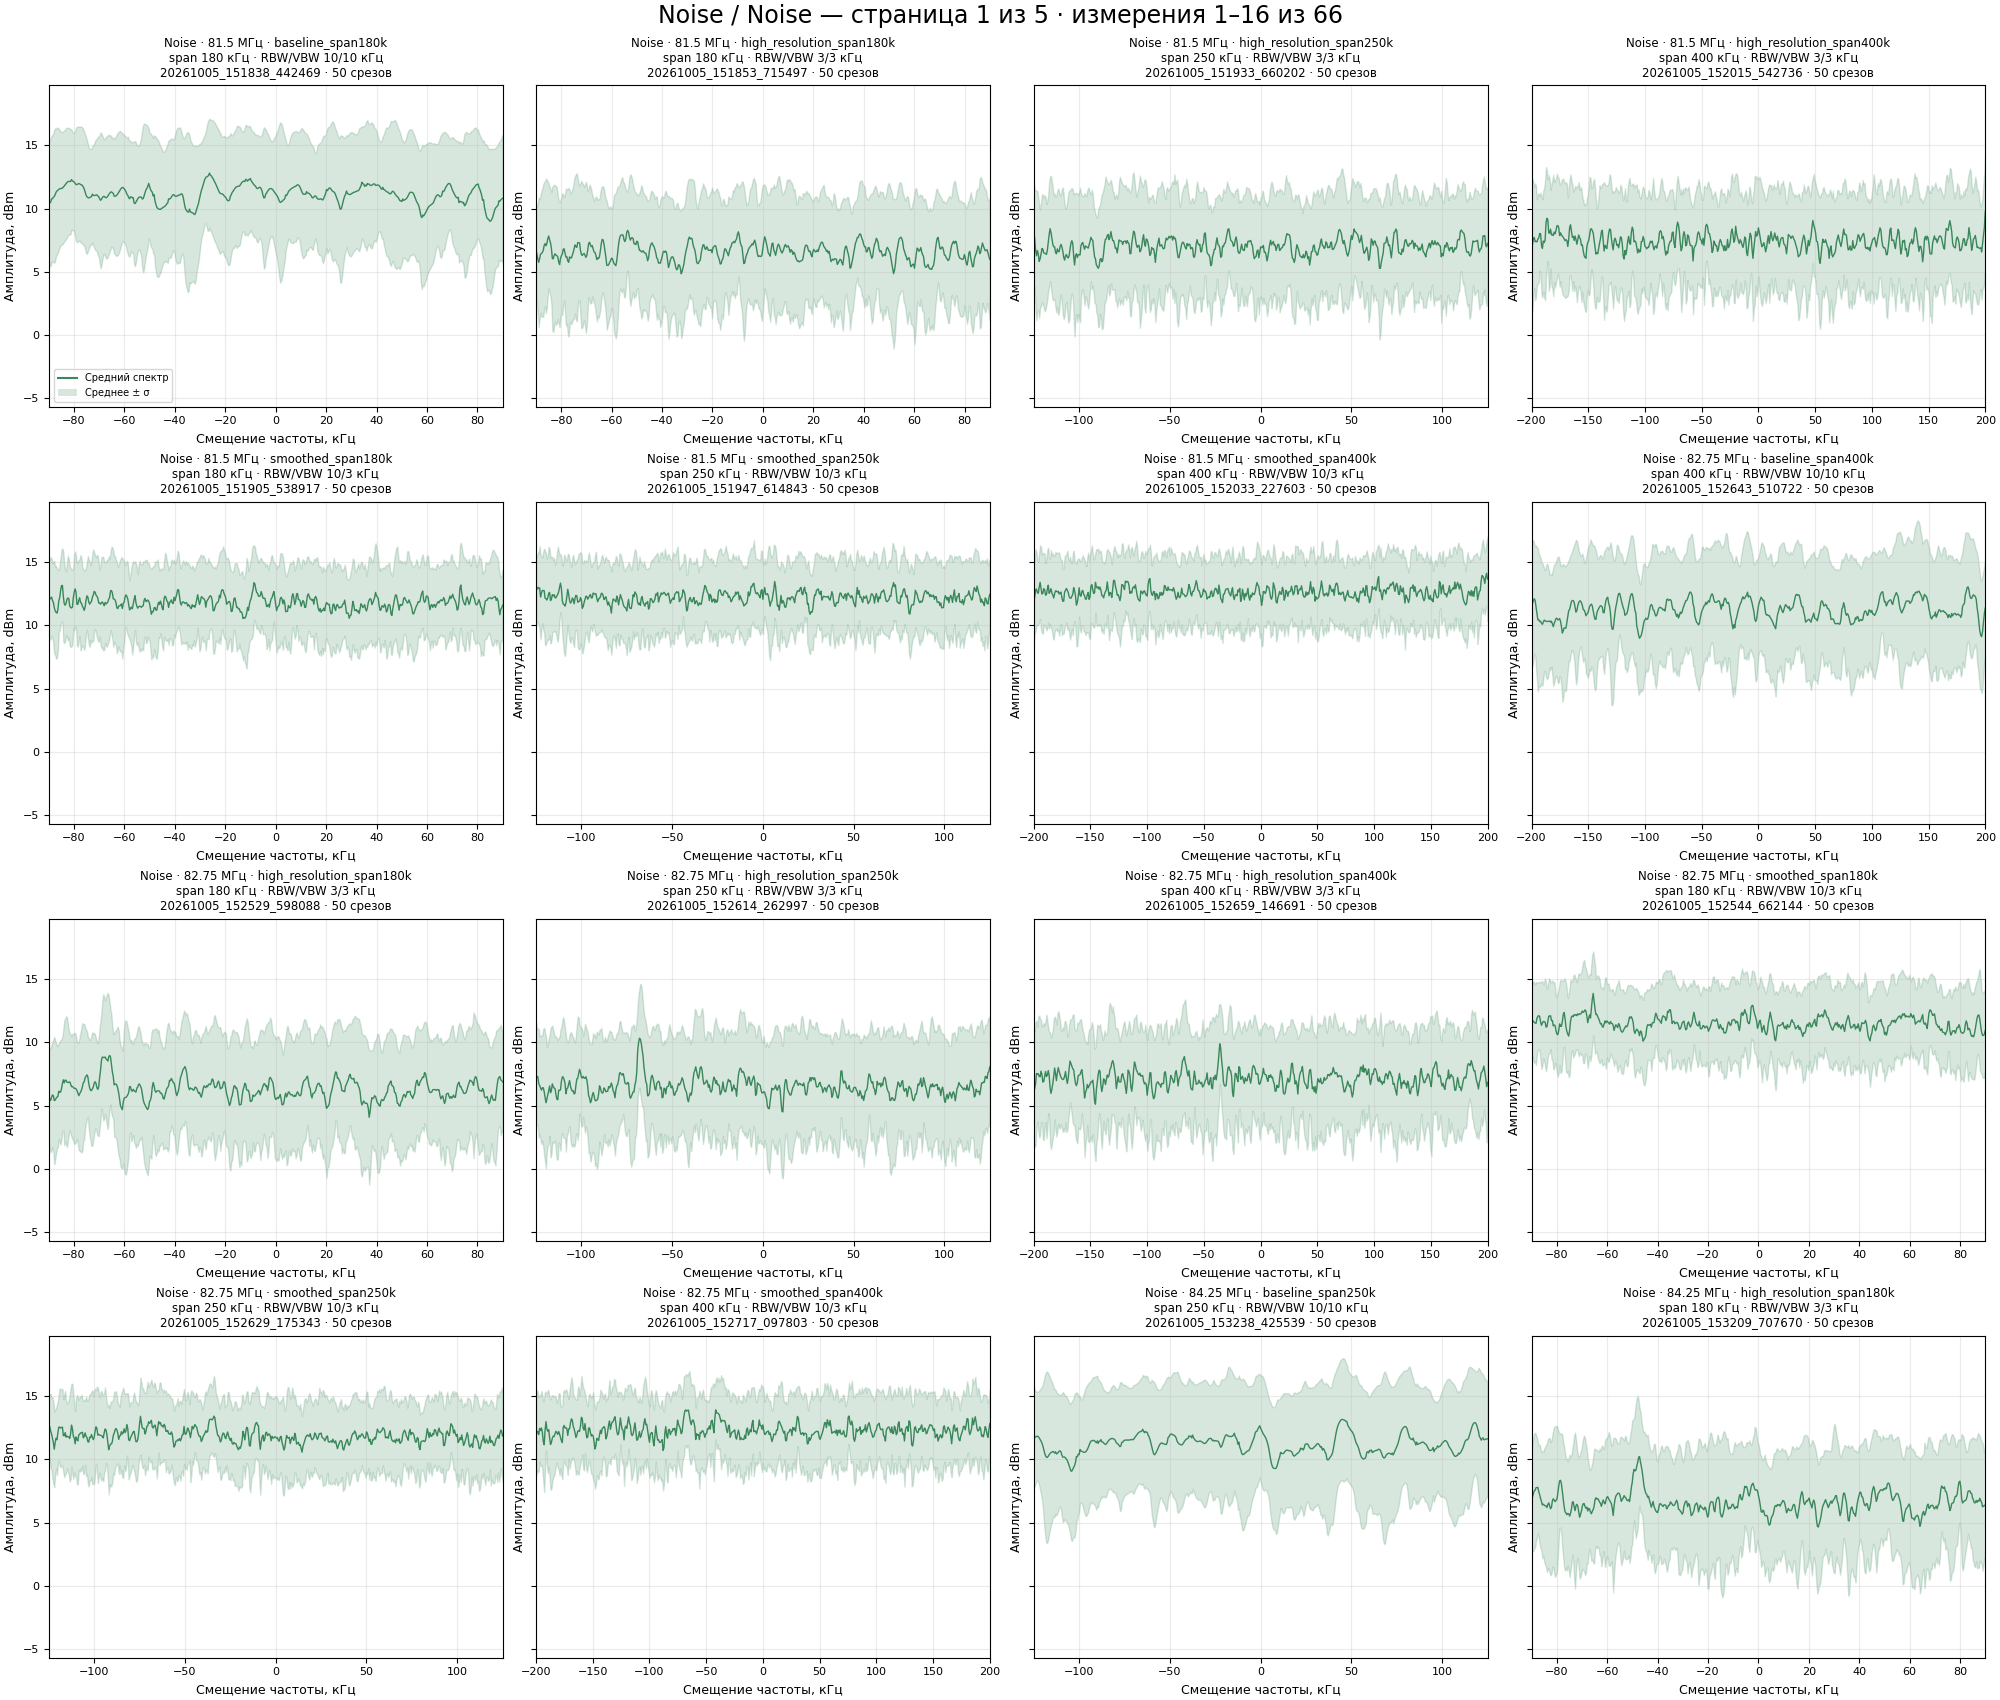

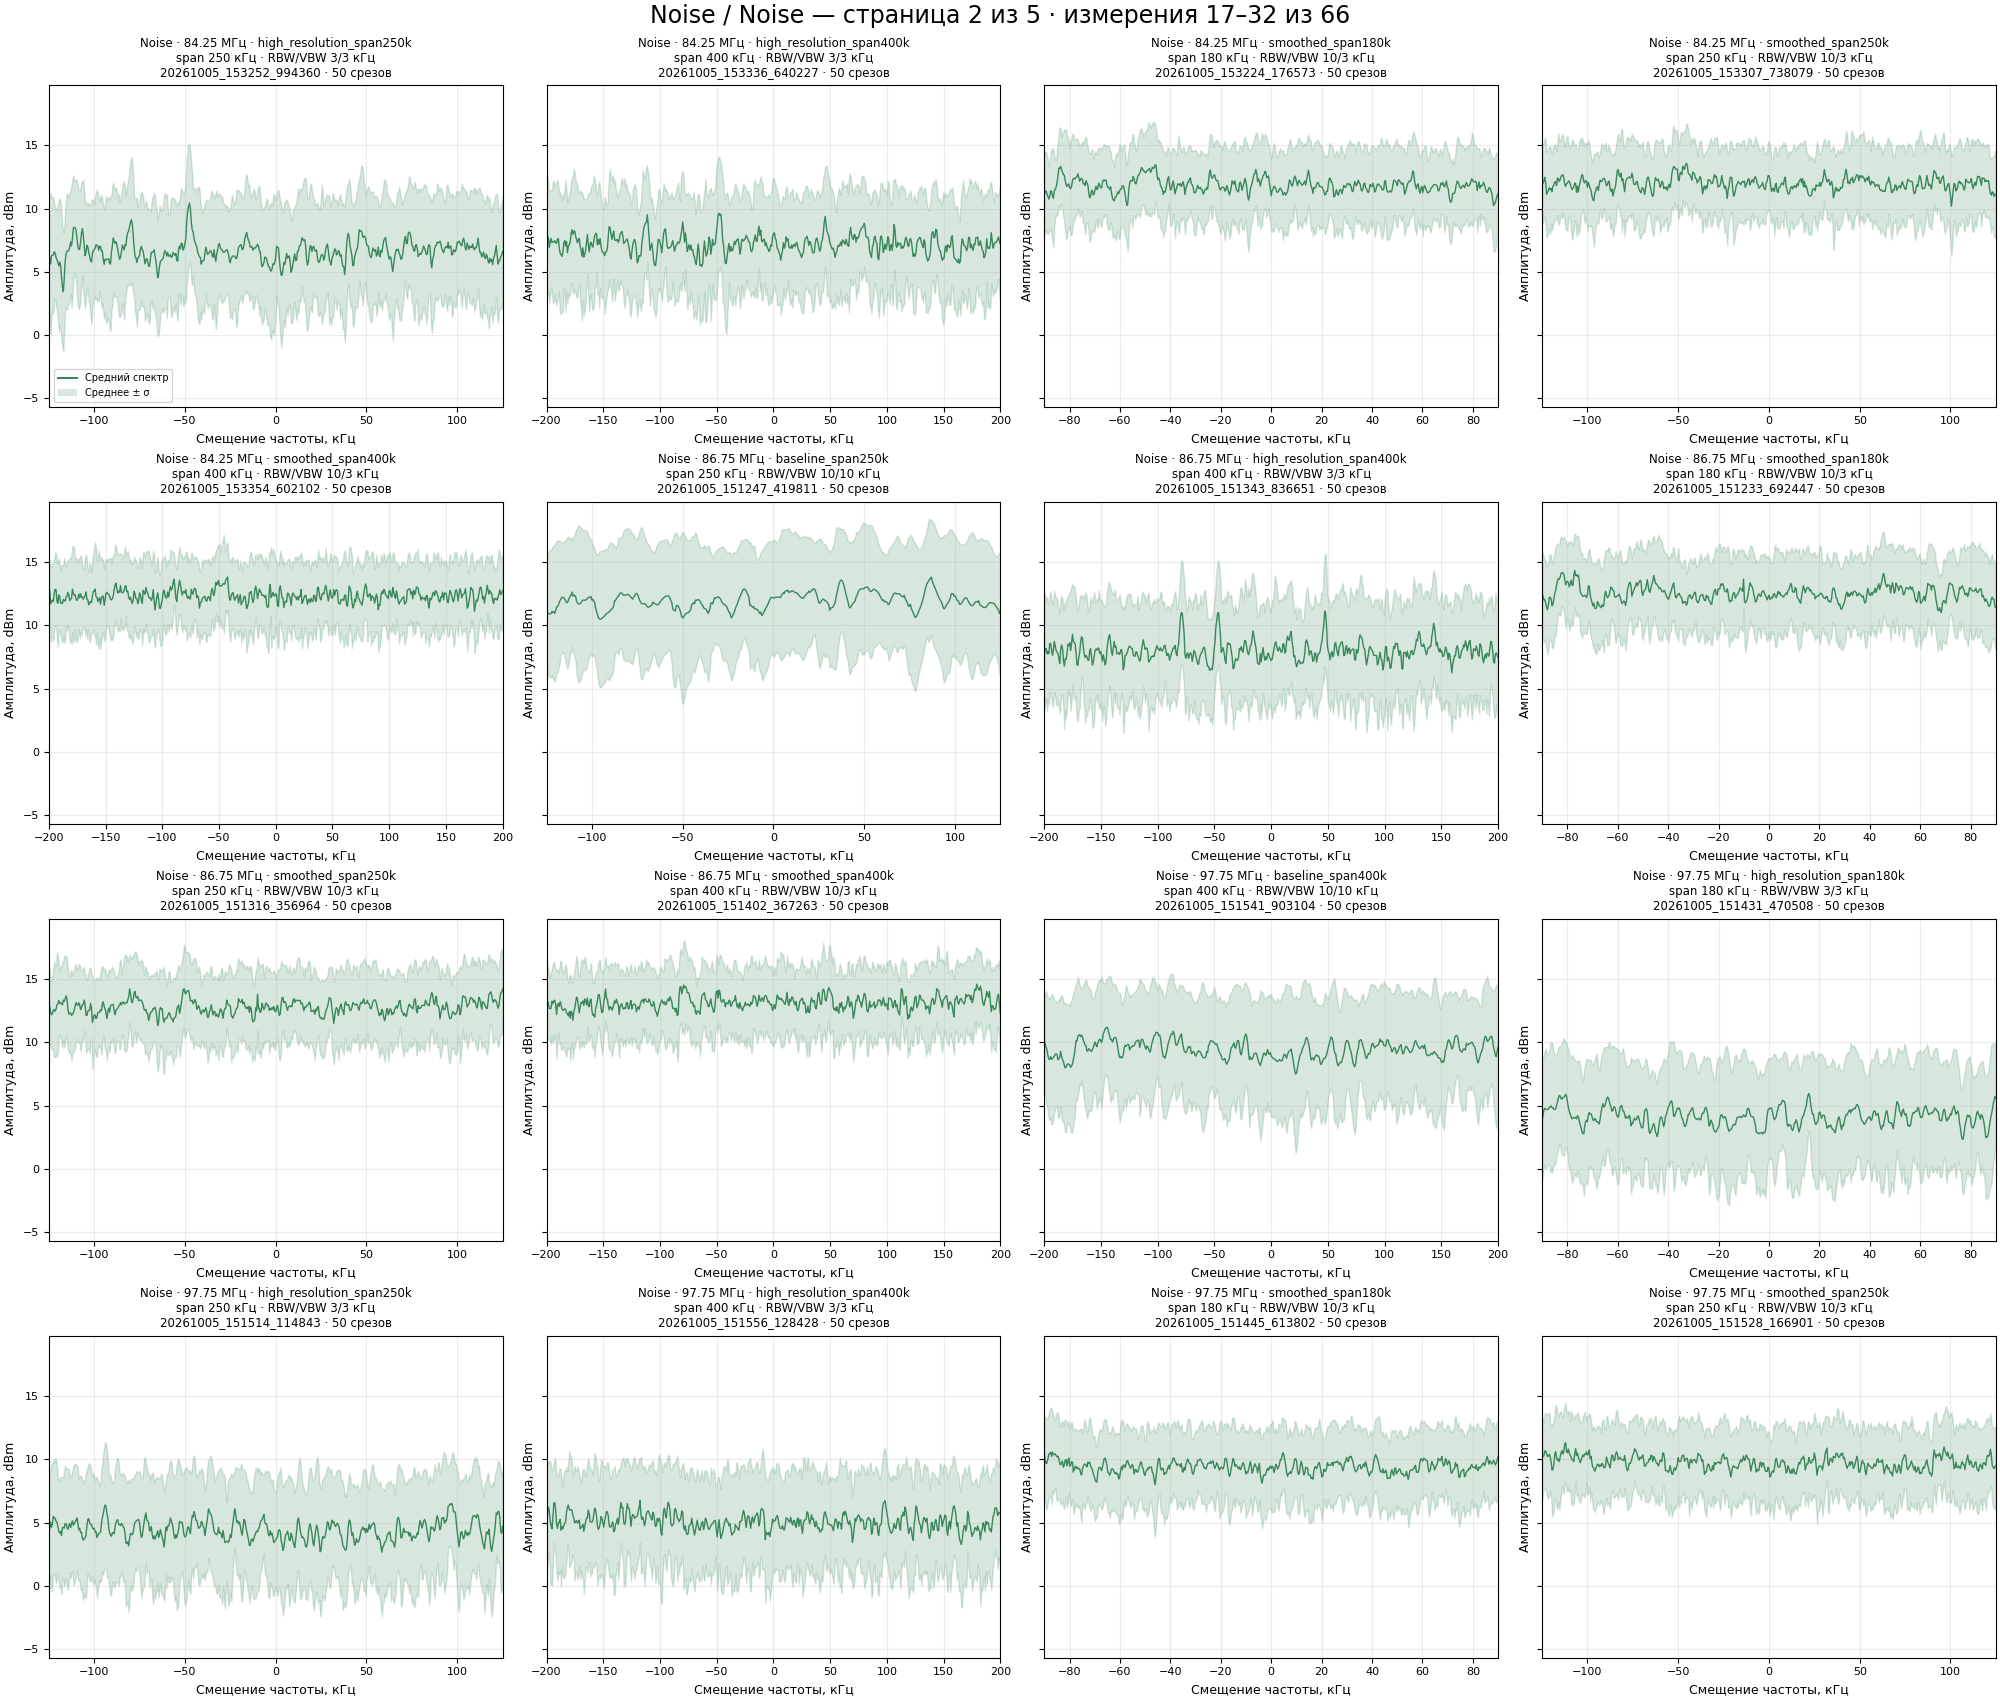

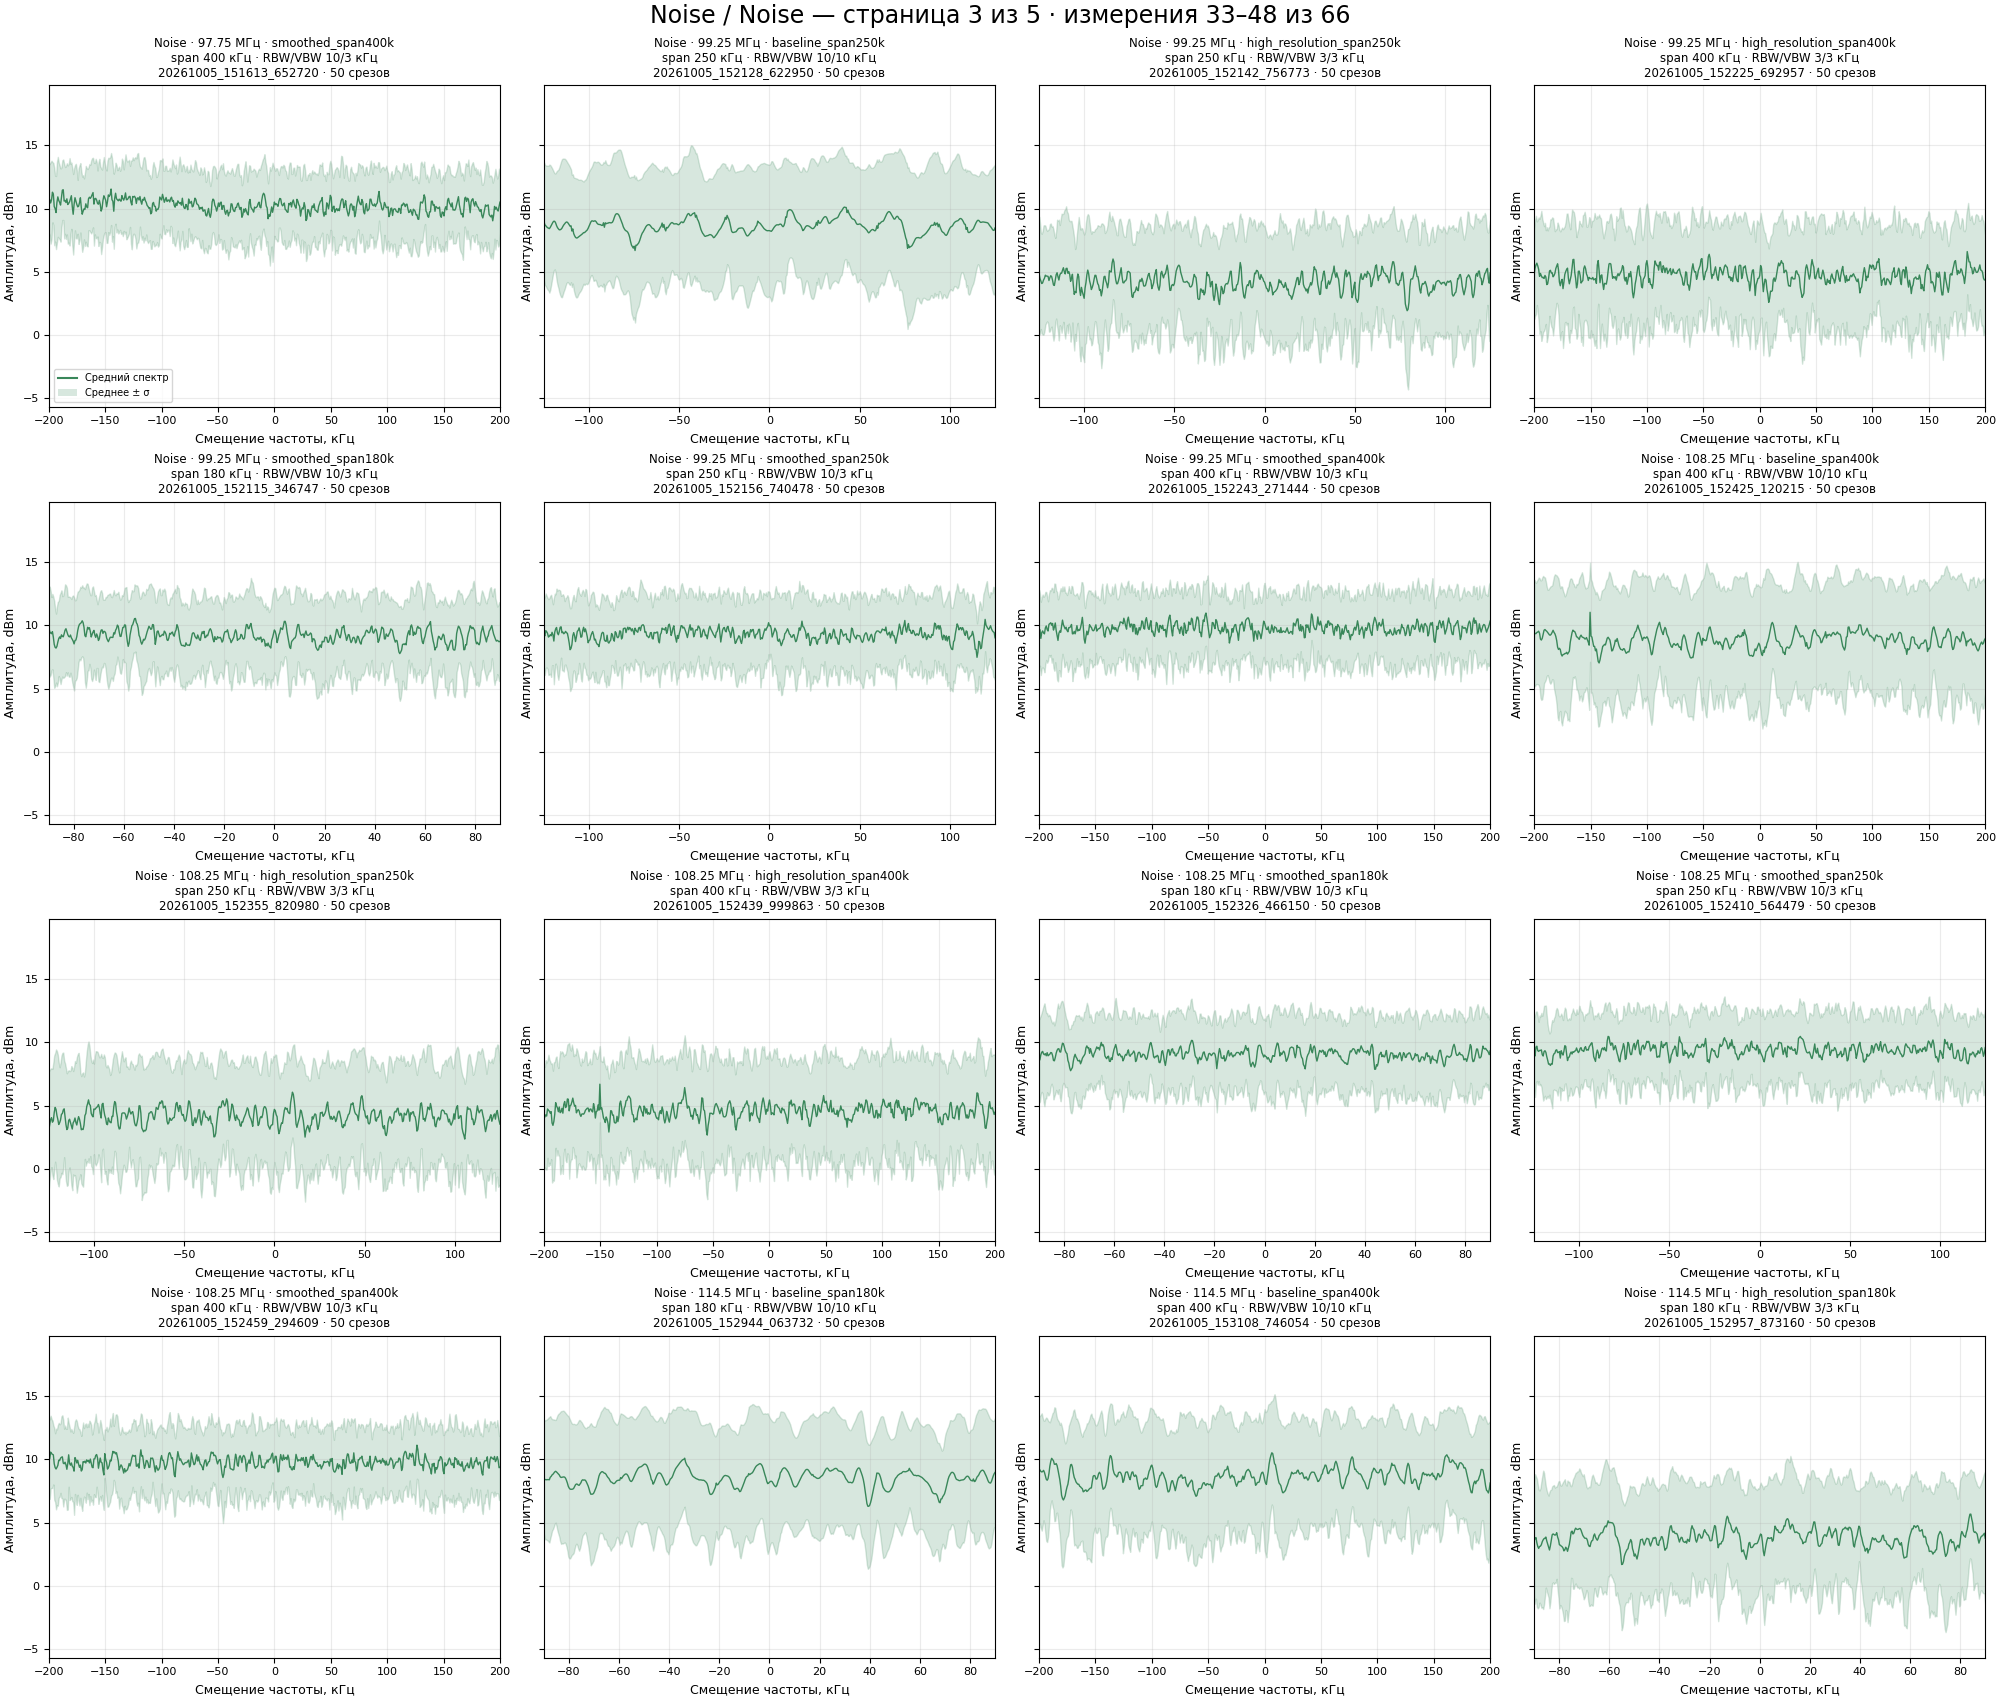

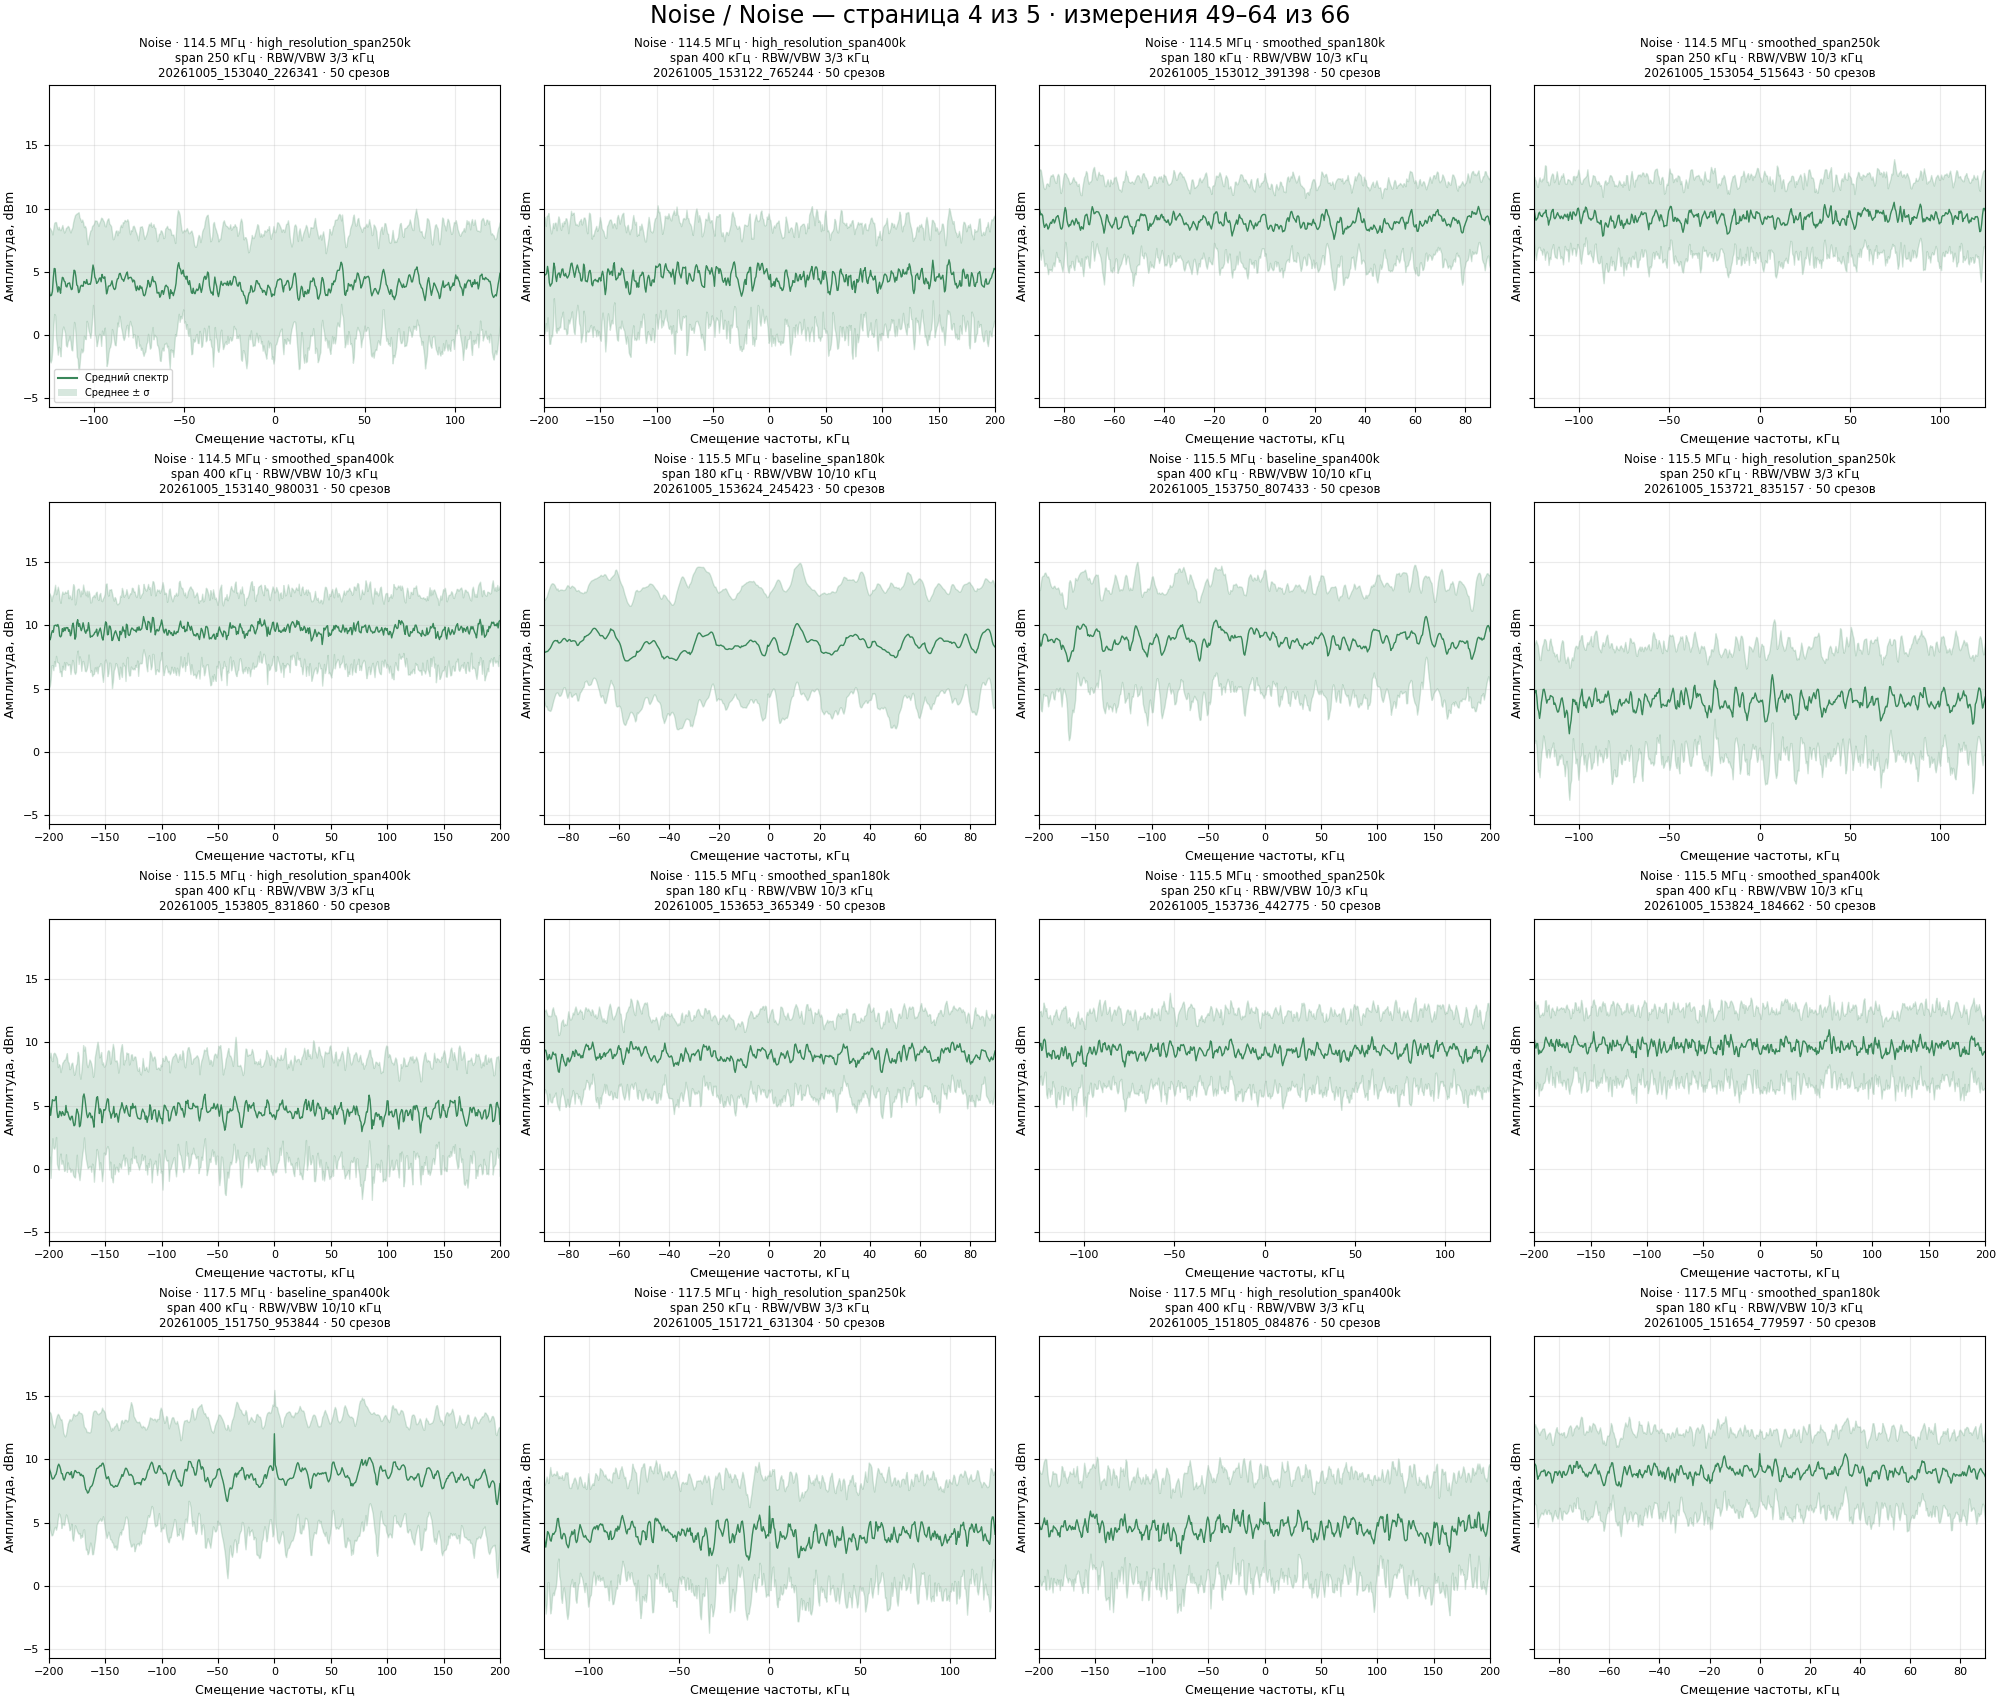

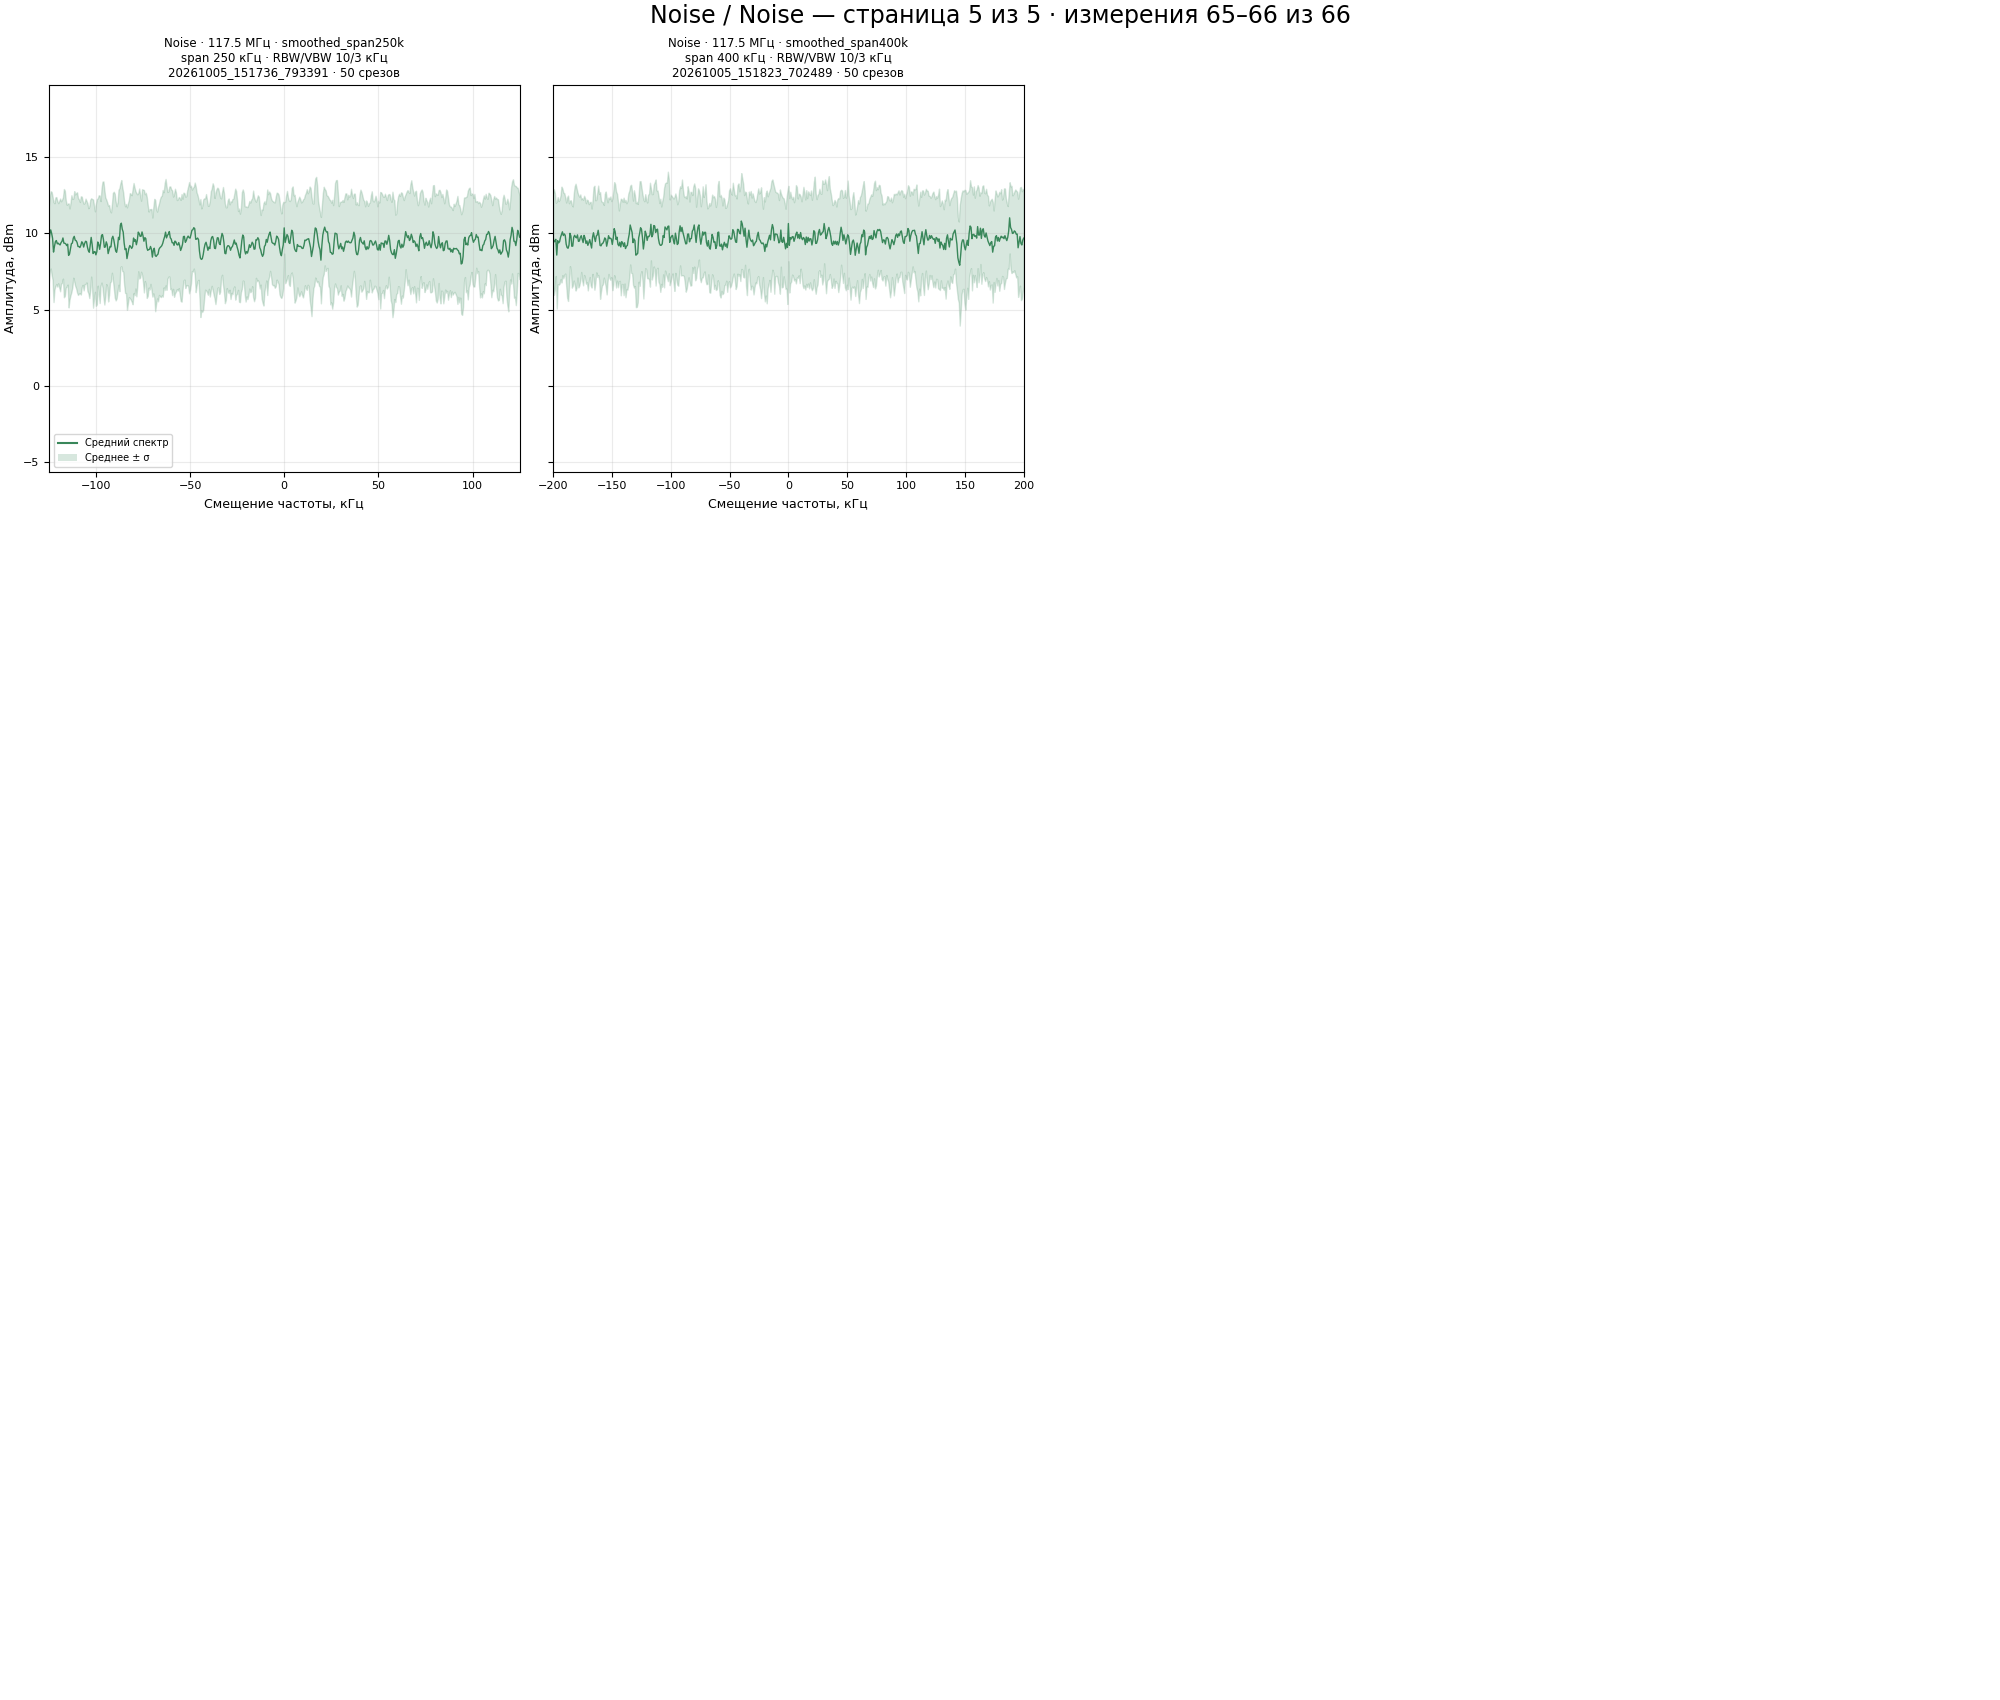

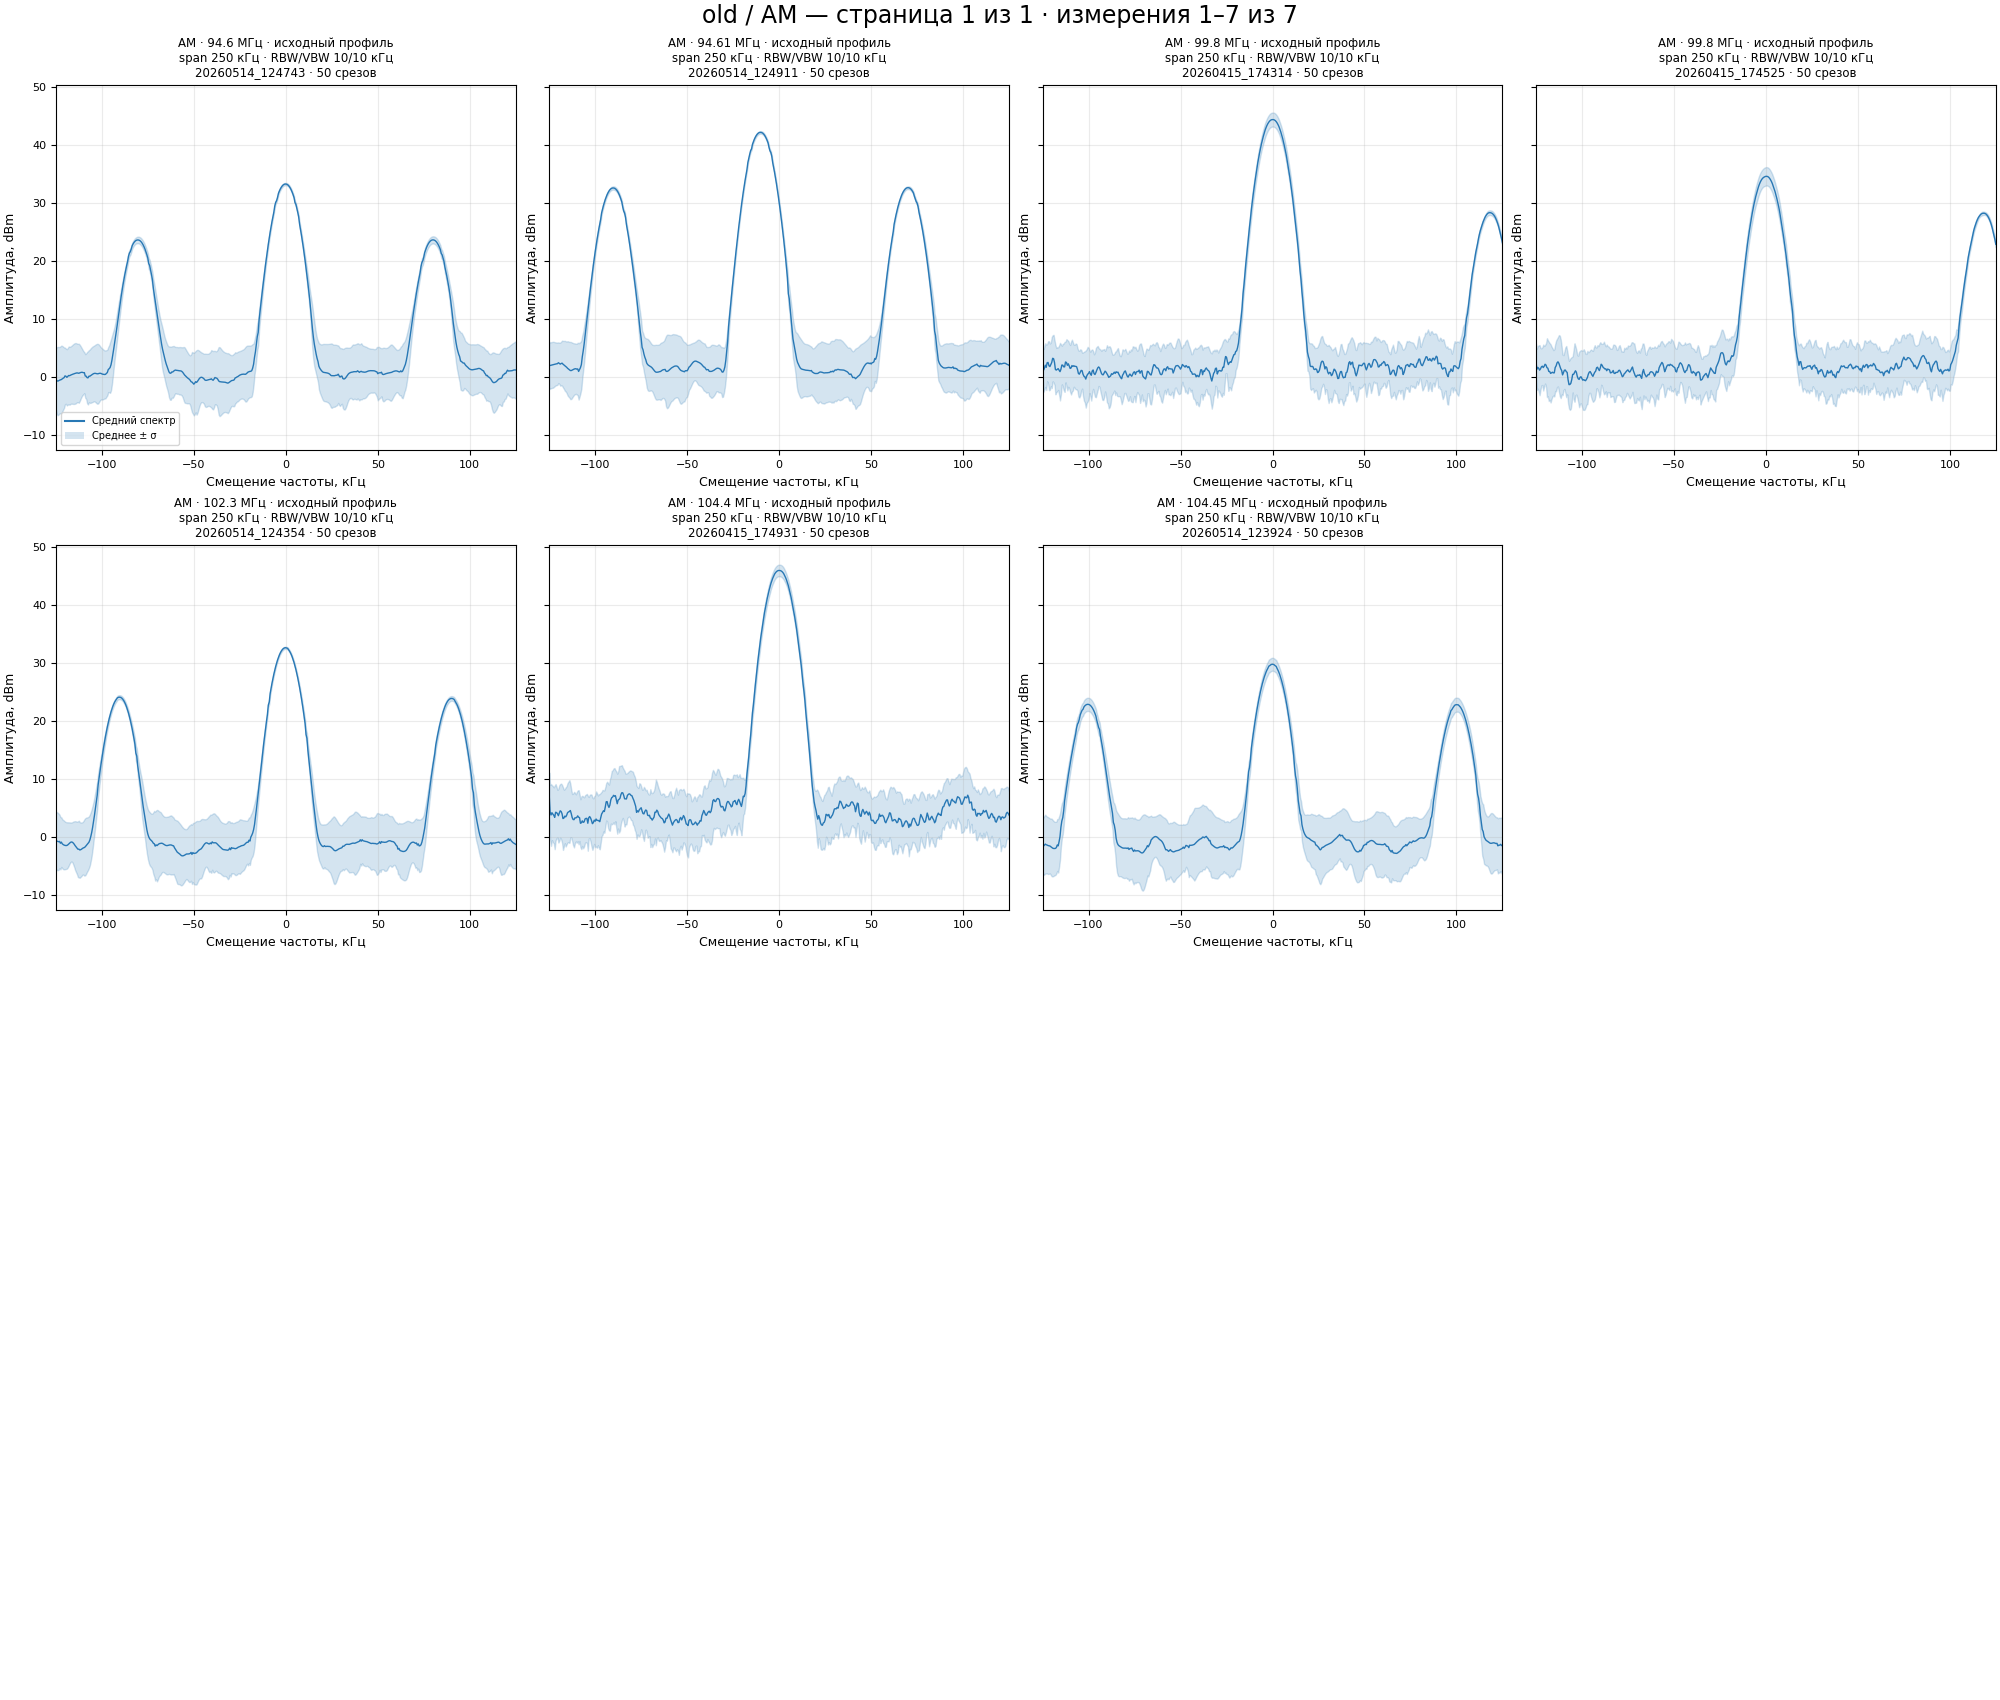

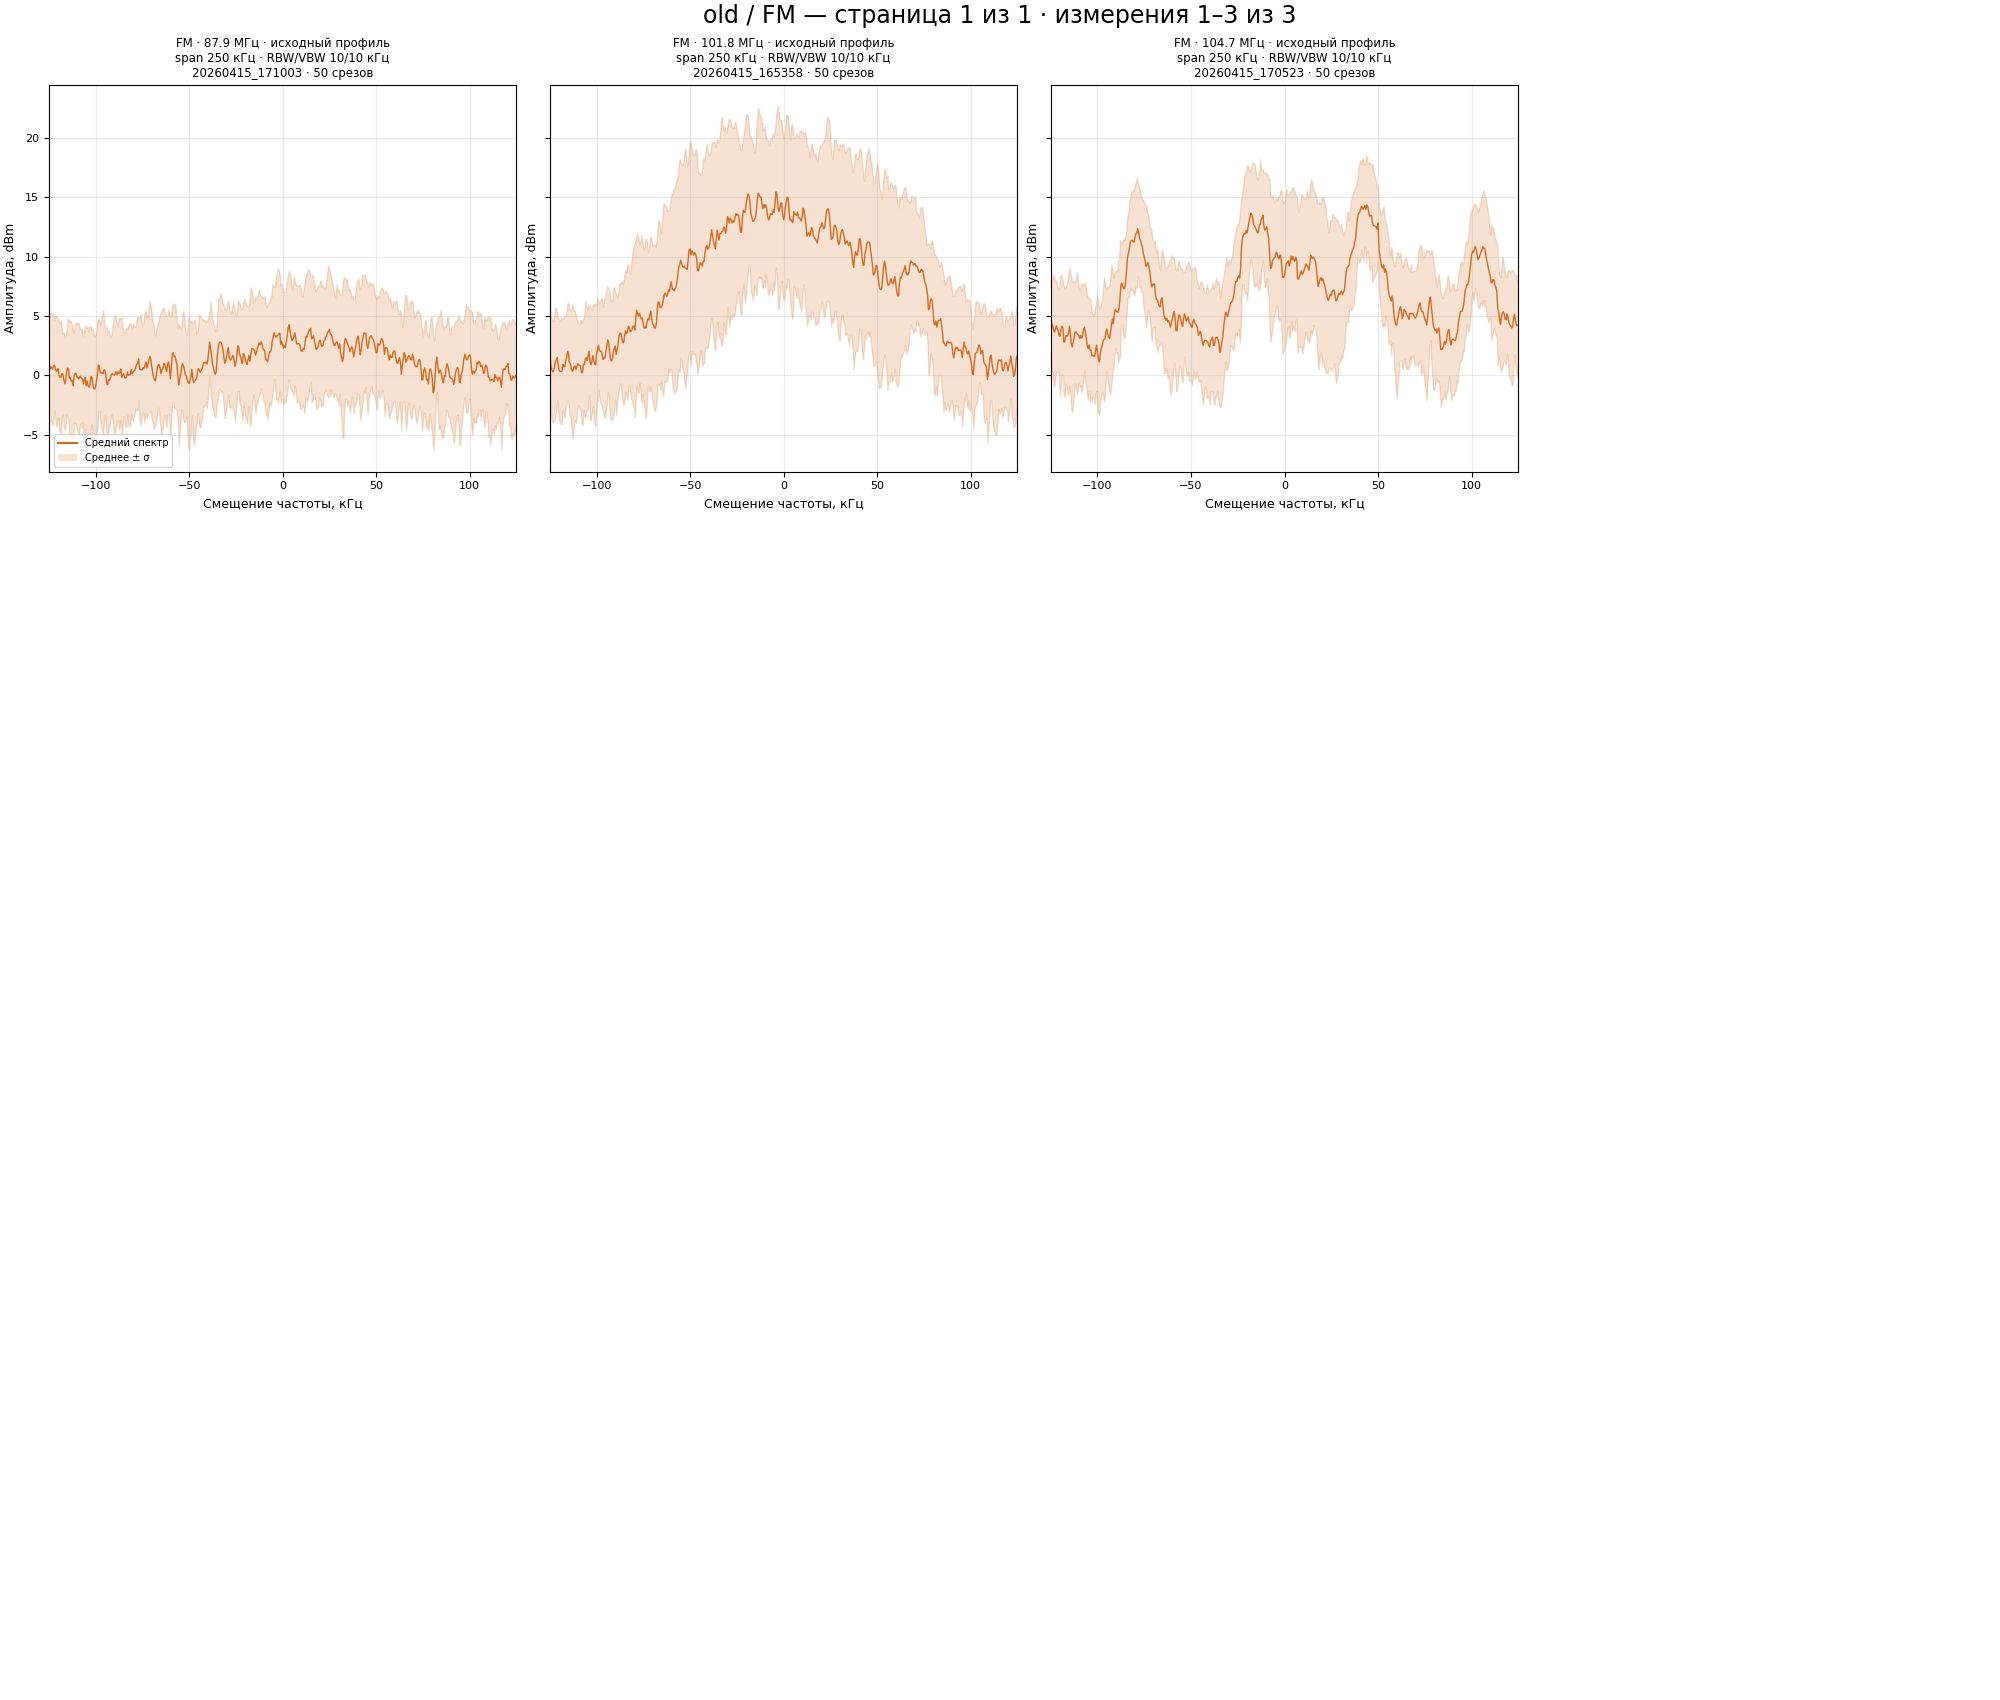

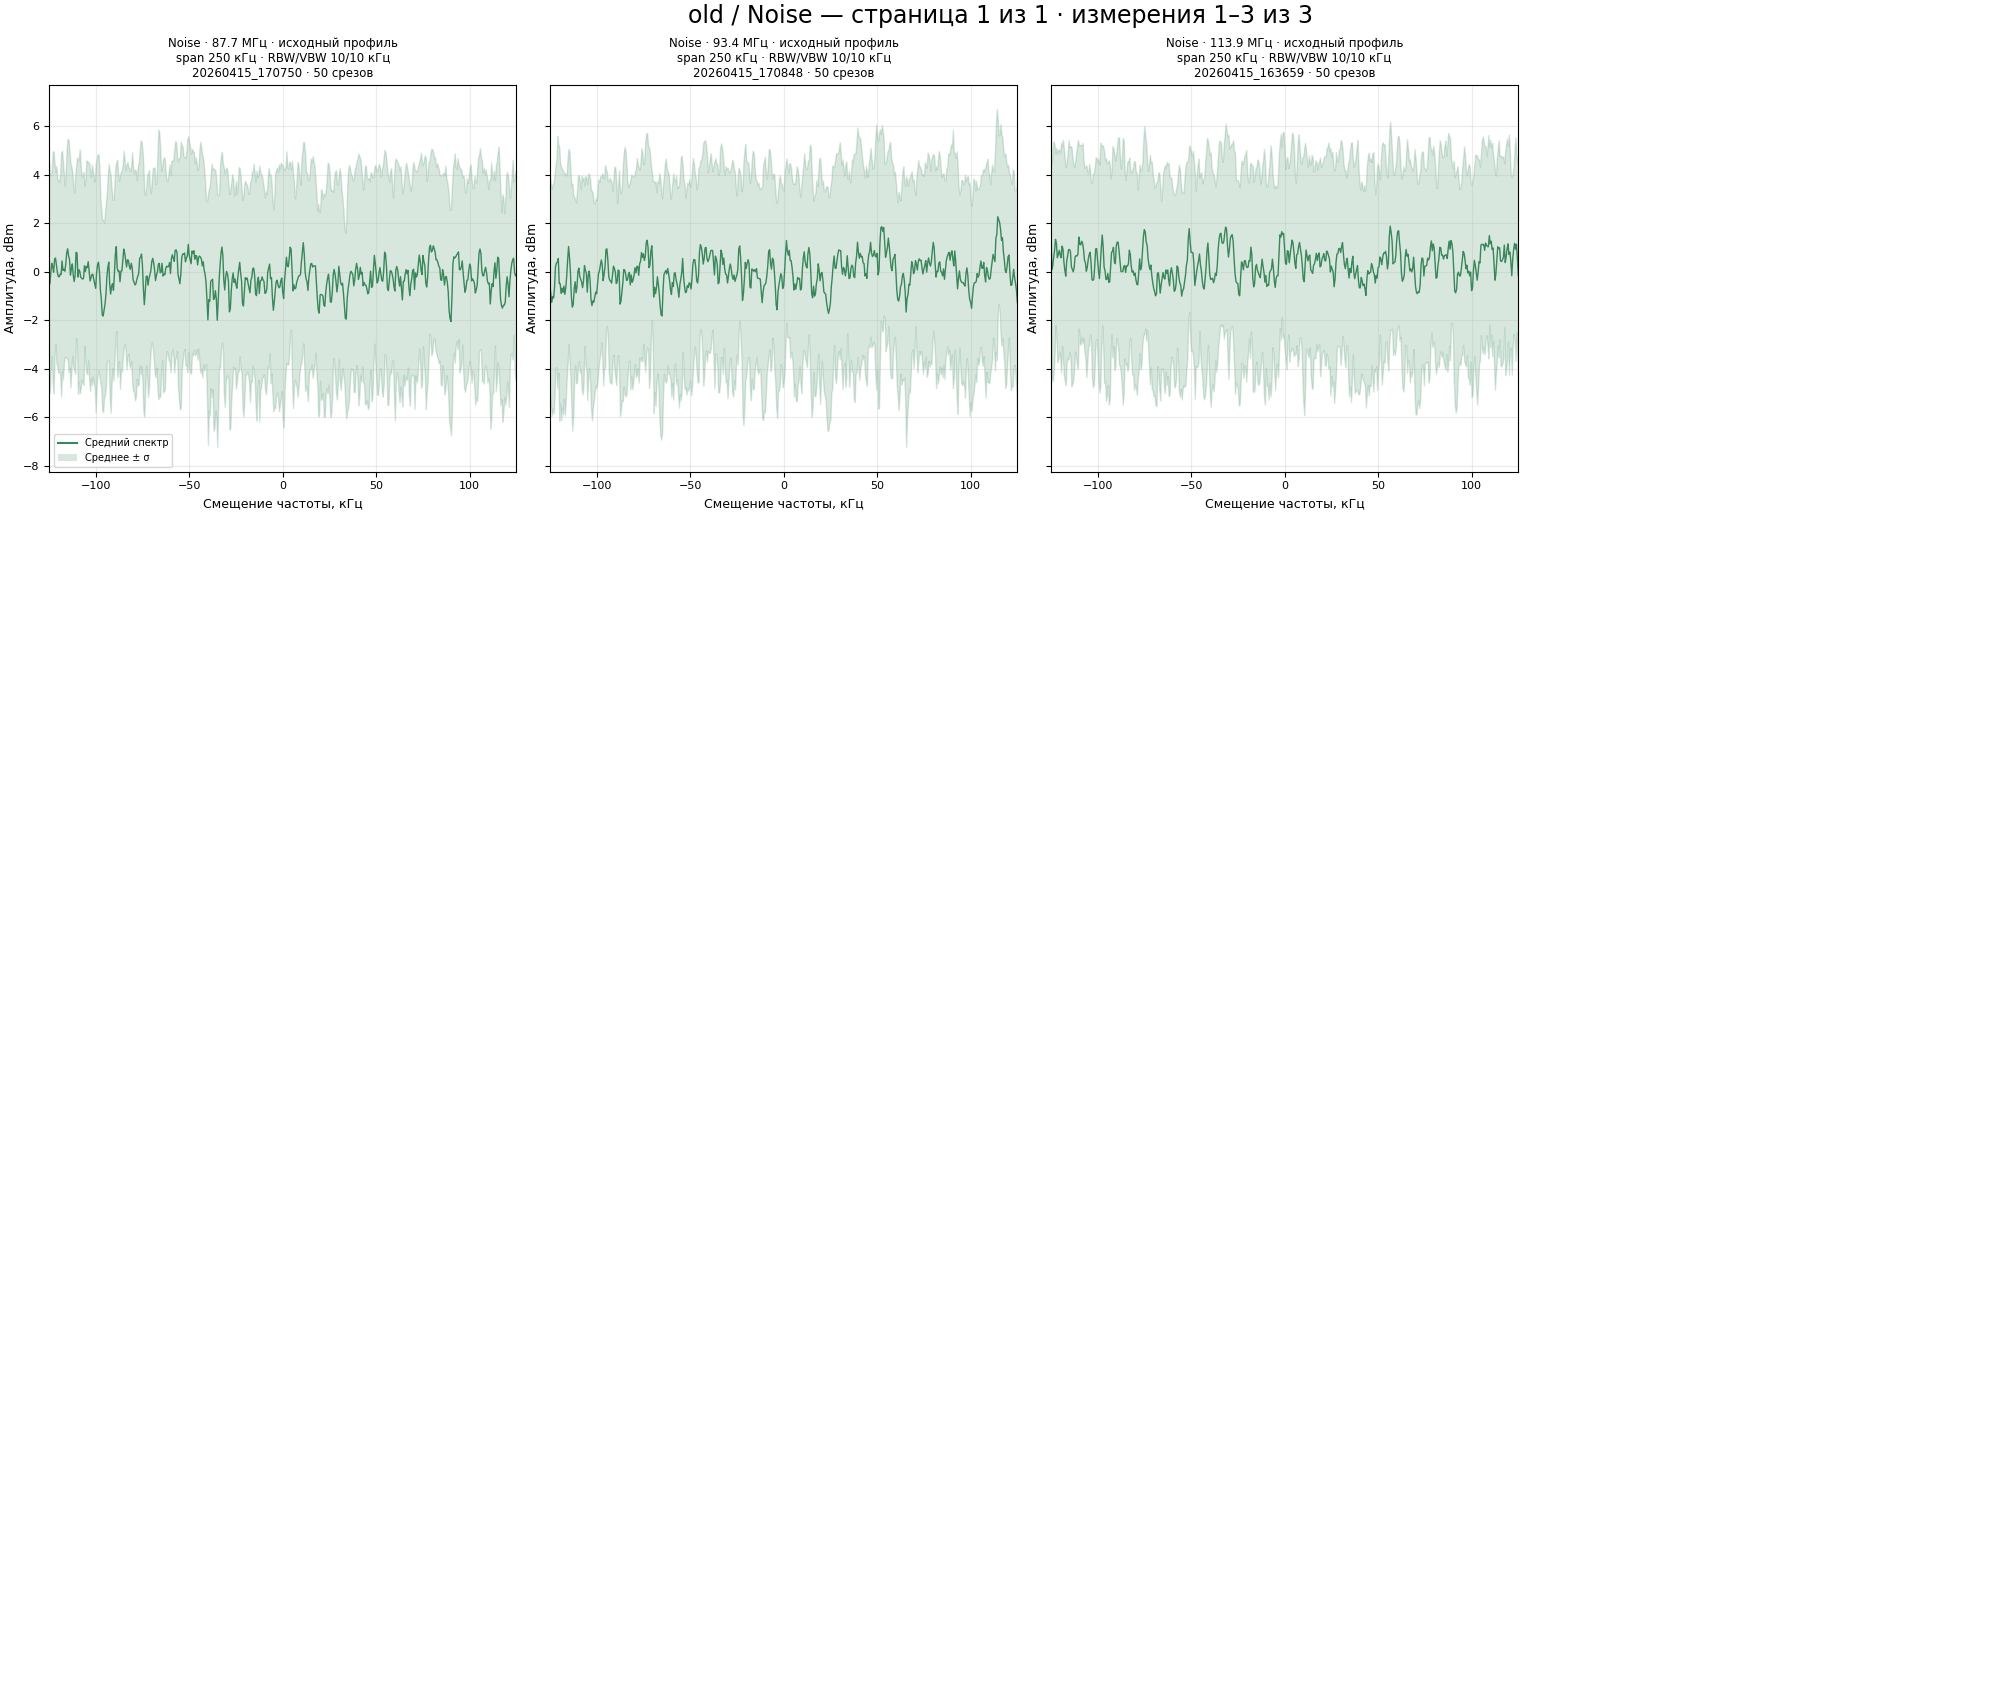

Показано измерений: 169; страниц: 14


In [6]:
# Все собранные записи, по 16 графиков на страницу.
gallery_pages = plot_spectrum_collections(measurements, spectra)

# Примеры фильтров для повторного запуска:
# plot_spectrum_collections(measurements, spectra, source_sets=["FM"], classes=["FM"])
# plot_spectrum_collections(measurements, spectra, classes=["FM"], centers_mhz=[97.2, 97.7])
# Доступные частоты ЧМ:
# sorted(measurements.loc[measurements["class_name"] == "FM", "center_freq_mhz"].unique())
